# Electricity consumption anomaly detection: from raw data to evaluated flags

**AT82.01 Computer Programming for Data Science and AI.** Midterm progress notebook (one notebook, top to bottom) and base for the final project.

**Research question.** How well do residual-based flags from an expected-consumption model match labeled anomalies in building electricity data, and which design choices (features, threshold, detector) improve that match?

**What an anomaly means here.** Use that is unusual given its context. It is not proof of waste, a fault or a saving. The output is a ranked list of periods worth a human check.

### How to run
1. Edit the **master settings cell** below (file paths only). Everything else follows from it.
2. Run all cells from top to bottom. Each part saves its results in the `outputs` folder and the next part reads those files, so a later part can be re-run alone: run the master settings cell and the memory helper, then jump to that part.
3. Between parts a small cell frees memory. Nothing else needs to be done by hand.

### The parts
| Part | What it does | Main files it saves |
|---|---|---|
| A | LEAD labels joined to GEPIII readings, zero runs, events | `lead_labels`, `lead_events.csv`, `labeled_building_ids.csv` |
| Checks | Basic data checks, daily and weekly patterns, why history must be built by time | `table_data_checks.csv`, `eda_profiles.png` |
| B | Hourly table, history by time, five predictors | `predictions`, `predictor_accuracy.csv` |
| C | Per-building error scores, one cut-off per predictor (validation only), flags | `cutoffs.json`, `flags` |
| D | Flags checked against the labeled events at the pre-set cut-offs | `eval_summary_test.csv`, `eval_by_length_test.csv` |
| E | The same check at equal alarm rates (fair comparison) | `eval_equal_rate_*_test.csv` |

### Rules that keep the test honest
- One cut in time: train before 2016-09-13, validation to 2016-11-06, test from 2016-11-07.
- Everything learned (fill values, typical values, model, error scales, cut-offs) uses training or validation rows only.
- Cut-offs are saved to files before the test period is scored (Part C), and are not changed afterwards.
- Part E sets thresholds from scores only (no labels), at equal alarm rates, because pooled cut-offs from Part C gave unequal alarm rates on test. This was found after looking at test results, and the report says so.
- LEAD labels come from human inspection of plots and LEAD derives from GEPIII, so the labels are a check against human judgment, not an independent truth.

## Master settings (the only cell you need to edit)

In [1]:
from pathlib import Path
import json, time, datetime, gc, types
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- paths (CHANGE; relative to the folder this notebook is in) ----
GEPIII_TRAIN   = "ashrae-energy-prediction/train.csv"
GEPIII_META    = "ashrae-energy-prediction/building_metadata.csv"
GEPIII_WEATHER = "ashrae-energy-prediction/weather_train.csv"
LEAD_FILE      = "ashrae-energy-prediction/train_features.csv"     # the labeled LEAD file
OUT_DIR        = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- time split (one cut in time for every building and every model) ----
GRID_START = pd.Timestamp("2016-01-01 00:00")
GRID_END   = pd.Timestamp("2016-12-31 23:00")
TRAIN_END  = pd.Timestamp("2016-09-13")      # train: before this
VAL_END    = pd.Timestamp("2016-11-07")      # validation: up to here; test: from here

# ---- data rules ----
ZERO_RUN_HOURS = 24            # a run of exact zeros this long is treated as missing, not as real low use
CONVERT_SITE0_TO_KWH = True    # GEPIII site 0 is in kBTU; LEAD stores it in kWh
KBTU_TO_KWH = 0.2931

# ---- which period the evaluation parts (D and E) score ----
EVAL_SPLIT = "test"            # "test" for the final numbers, "val" while exploring

T_START = time.time()

### Memory helper
GEPIII has tens of millions of rows. After each part this helper deletes the large tables that part created (all results are already saved to files), so the next part starts clean. It keeps the settings above.

In [2]:
def free_memory(label=""):
    for k in list(globals()):
        if k.startswith("_") or k in _KEEP:
            continue
        if isinstance(globals()[k], types.ModuleType):
            continue
        del globals()[k]
    gc.collect()
    print(f"[memory freed] {label} | elapsed {(time.time() - T_START) / 60:.1f} min")

_KEEP = set(globals()) | {"_KEEP"}
print("settings loaded; files will be written to", OUT_DIR.resolve())

settings loaded; files will be written to /Users/barnnitashrestha/DSAI/CP-LAB/Project/outputs


# Part A: LEAD 1.0 labels, join, and events (version 2)

What this notebook does:
1. Opens the LEAD 1.0 file and shows what is in it.
2. Keeps only the buildings that LEAD labels. Buildings outside the file have no labels, so they cannot be treated as normal.
3. Puts GEPIII readings in the same unit as LEAD (site 0 is stored in kBTU in GEPIII and in kWh in LEAD).
4. Checks that LEAD's readings match GEPIII's, and explains the rows that do not.
5. Marks long runs of zero readings.
6. Turns labeled hours into events and sorts them into length groups.
7. Counts events per length group, split (train, validation, test) and building group (all, Education).
8. Saves the labels, the events and the count tables.

Run the cells in order and read each printed result before moving on. Cells marked **CHANGE** may need your paths or column names.

Nothing here uses test results to make decisions. It only counts and joins.

## 0. Settings for this part

The shared paths, dates and rules are in the master settings cell at the top of the notebook. Only settings specific to this part are here.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd

# ---- paths (CHANGE to where your files are; these are relative to the folder this notebook is in) ----

# ---- split dates (same as the project plan) ----

# ---- rules ----
MIN_TEST_EVENTS = 20           # warn if a length group has fewer test events than this
LENGTH_BINS   = [0, 1, 3, 12, np.inf]
LENGTH_LABELS = ["1 h", "2-3 h", "4-12 h", ">12 h"]

# ---- units ----

# ---- LEAD column names: leave as None to detect automatically, or type the real name ----
LEAD_BUILDING_COL = None
LEAD_TIME_COL     = None
LEAD_READING_COL  = None
LEAD_LABEL_COLS   = None       # a list such as ["anomaly"]; None = detect automatically

## 1. Open the LEAD file and look at it

In [4]:
lead_cols_all = pd.read_csv(LEAD_FILE, nrows=0).columns.tolist()
print("LEAD file has", len(lead_cols_all), "columns. First 12:", lead_cols_all[:12])

LEAD file has 57 columns. First 12: ['building_id', 'timestamp', 'meter_reading', 'anomaly', 'site_id', 'primary_use', 'square_feet', 'year_built', 'floor_count', 'air_temperature', 'cloud_coverage', 'dew_temperature']


The LEAD file can have many feature columns. Only the building, time, reading and label columns are needed here, so only those are loaded.

In [5]:
def pick(cands, cols, what, given=None):
    if given is not None:
        if given not in cols:
            raise KeyError(f"{what} column '{given}' is not in the file. Columns: {list(cols)}")
        return given
    for c in cands:
        if c in cols:
            return c
    raise KeyError(f"Could not find a {what} column. Columns are: {list(cols)}. Set it by hand in Section 0.")

cols = lead_cols_all
b_col = pick(["building_id", "building", "bldg_id", "meter_id"], cols, "building", LEAD_BUILDING_COL)
t_col = pick(["timestamp", "time", "datetime", "date"], cols, "time", LEAD_TIME_COL)

r_col = None
try:
    r_col = pick(["meter_reading", "reading", "value", "electricity"], cols, "reading", LEAD_READING_COL)
except KeyError:
    print("No reading column found in LEAD. The match check in Section 3 will be skipped.")

if LEAD_LABEL_COLS is not None:
    label_cols = list(LEAD_LABEL_COLS)
else:
    guesses = ["anomaly", "point_anomaly", "sequence_anomaly", "anomaly_point", "anomaly_sequence",
               "label", "is_anomaly", "anomalous"]
    label_cols = [c for c in guesses if c in cols]
if not label_cols:
    raise KeyError(f"Could not find a label column. Columns are: {cols}. Set LEAD_LABEL_COLS in Section 0.")

use = [b_col, t_col] + ([r_col] if r_col else []) + label_cols + (["meter"] if "meter" in cols else [])
lead_raw = pd.read_csv(LEAD_FILE, usecols=use)
print("shape:", lead_raw.shape)
print("building:", b_col, "| time:", t_col, "| reading:", r_col, "| labels:", label_cols)
for c in label_cols:
    print()
    print(f"values in '{c}':")
    print(lead_raw[c].value_counts(dropna=False).head(10))
lead_raw.head()

shape: (1749494, 4)
building: building_id | time: timestamp | reading: meter_reading | labels: ['anomaly']

values in 'anomaly':
anomaly
0    1712198
1      37296
Name: count, dtype: int64


,building_id,timestamp,meter_reading,anomaly
0,1,2016-01-01 00:00:00,NaN,0
1,32,2016-01-01 00:00:00,NaN,0
2,41,2016-01-01 00:00:00,NaN,0
3,55,2016-01-01 00:00:00,NaN,0
4,69,2016-01-01 00:00:00,NaN,0


### Tidy the LEAD table
- Keep electricity only if there is a `meter` column.
- Make the time a real date-time.
- A row is labeled anomalous if any label column is above 0.

In [6]:
lead = lead_raw.copy()

if "meter" in lead.columns:
    print("meter values:", lead["meter"].unique()[:10])
    lead = lead[lead["meter"] == 0]

rename = {b_col: "building_id", t_col: "timestamp"}
if r_col is not None:
    rename[r_col] = "lead_reading"
lead = lead.rename(columns=rename)

lead["timestamp"] = pd.to_datetime(lead["timestamp"])
lead["building_id"] = lead["building_id"].astype("int32")

for c in label_cols:
    lead[c] = pd.to_numeric(lead[c], errors="coerce").fillna(0)
lead["label"] = (lead[label_cols].gt(0).any(axis=1)).astype("int8")

lead = lead.drop_duplicates(["building_id", "timestamp"])

labeled_buildings = set(lead["building_id"].unique())
print("LEAD rows:", len(lead), "| labeled buildings:", len(labeled_buildings))
print("time range:", lead["timestamp"].min(), "to", lead["timestamp"].max())
print("labeled hours:", int(lead["label"].sum()), f"({lead['label'].mean()*100:.2f}% of rows)")

LEAD rows: 1749494 | labeled buildings: 200
time range: 2016-01-01 00:00:00 to 2016-12-31 23:00:00
labeled hours: 37296 (2.13% of rows)


**Important.** The paper describes 1,413 labeled meters, but the file may label fewer buildings (a labeled part and a part with hidden labels). Everything below uses only the buildings that this file labels. Buildings outside the file have no labels, so treating their hours as normal would be wrong.

## 2. Open the GEPIII electricity data and building information

In [7]:
gep = pd.read_csv(GEPIII_TRAIN, usecols=["building_id", "meter", "timestamp", "meter_reading"],
                  dtype={"building_id": "int32", "meter": "int8", "meter_reading": "float32"})
gep = gep[gep["meter"] == 0].drop(columns="meter")
gep["timestamp"] = pd.to_datetime(gep["timestamp"])
gep = gep.drop_duplicates(["building_id", "timestamp"])
print("GEPIII electricity rows (all buildings):", len(gep), "| buildings:", gep["building_id"].nunique())

meta = pd.read_csv(GEPIII_META)

# keep only the buildings that LEAD labels
gep = gep[gep["building_id"].isin(labeled_buildings)].copy()
print("GEPIII rows in labeled buildings:", len(gep), "| buildings:", gep["building_id"].nunique())

missing_in_gep = labeled_buildings - set(gep["building_id"].unique())
if missing_in_gep:
    print("WARNING: these labeled buildings are not in GEPIII electricity data:", sorted(missing_in_gep)[:20])

lab_meta = meta[meta["building_id"].isin(labeled_buildings)]
print()
print("Labeled buildings by use type:")
print(lab_meta["primary_use"].value_counts())
print()
print("Labeled buildings by site:", lab_meta["site_id"].value_counts().sort_index().to_dict())

GEPIII electricity rows (all buildings): 12060910 | buildings: 1413
GEPIII rows in labeled buildings: 1749494 | buildings: 200

Labeled buildings by use type:
primary_use
Education                        80
Office                           62
Entertainment/public assembly    23
Lodging/residential              13
Public services                   7
Healthcare                        5
Services                          3
Parking                           2
Manufacturing/industrial          2
Other                             1
Food sales and service            1
Religious worship                 1
Name: count, dtype: int64

Labeled buildings by site: {0: 8, 1: 16, 2: 21, 3: 11, 4: 2, 5: 24, 7: 1, 8: 3, 9: 52, 10: 2, 12: 1, 13: 11, 14: 47, 15: 1}


### Put readings in the same unit as LEAD
GEPIII stores site 0 in kBTU. LEAD stores it in kWh (a factor of 0.2931). Use kWh everywhere in your own pipeline too, so errors are comparable across sites.

In [8]:
gep = gep.merge(meta[["building_id", "site_id"]], on="building_id", how="left")
gep["meter_reading_raw"] = gep["meter_reading"]
if CONVERT_SITE0_TO_KWH:
    is0 = gep["site_id"].eq(0)
    gep.loc[is0, "meter_reading"] = (gep.loc[is0, "meter_reading_raw"] * KBTU_TO_KWH).astype("float32")
    print("Converted", int(is0.sum()), "rows at site 0 from kBTU to kWh.")

Converted 70272 rows at site 0 from kBTU to kWh.


## 3. Check that LEAD matches GEPIII
Rows are compared on building and time. Three groups of rows are explained separately, because they are expected differences and not join errors:
1. LEAD readings that are blank.
2. Labeled hours where LEAD shows a reading of exactly 1.0.
3. Everything else, which should match.

In [9]:
keys = ["building_id", "timestamp"]
have_reading = "lead_reading" in lead.columns
both = gep.merge(lead[keys + (["lead_reading"] if have_reading else []) + ["label"]], on=keys, how="outer", indicator=True)
in_gep = both["meter_reading"].notna()
print(both["_merge"].value_counts())
print("Share of labeled-building GEPIII rows found in LEAD:",
      round((both["_merge"].eq("both") & in_gep).sum() / in_gep.sum(), 4))

if have_reading:
    m = both[both["_merge"] == "both"].copy()
    n = len(m)
    blank = m["lead_reading"].isna()
    one_on_label = m["lead_reading"].eq(1.0) & m["label"].eq(1)
    comp = m[~blank & ~one_on_label]

    def same(a, b):
        return np.isclose(a, b, rtol=1e-3, atol=1e-2)

    print()
    print(f"Rows in both files: {n}")
    print(f"  LEAD reading blank:                    {int(blank.sum())} ({blank.mean()*100:.2f}%), labeled anomalous among them: {int(m.loc[blank, 'label'].sum())}")
    print(f"  LEAD reading exactly 1.0 on labeled hours: {int(one_on_label.sum())} ({one_on_label.mean()*100:.2f}%)")
    print(f"  Compared directly:                     {len(comp)}")
    eq = same(comp["meter_reading"], comp["lead_reading"])
    print(f"  Equal after unit conversion:           {eq.mean()*100:.2f}%")
    if "meter_reading_raw" in m.columns:
        eq_raw = same(comp["meter_reading_raw"], comp["lead_reading"])
        print(f"  Equal without unit conversion:         {eq_raw.mean()*100:.2f}%")
    if eq.mean() < 0.99:
        print("WARNING: readings still do not match well after these explanations. Find out why before continuing (ids, units, time zone).")
        print(comp.loc[~eq].head())
    else:
        print("OK: the labels sit on the right rows.")
else:
    print("LEAD has no reading column, so the values could not be compared.")
del both

_merge
both          1749494
left_only           0
right_only          0
Name: count, dtype: int64
Share of labeled-building GEPIII rows found in LEAD: 1.0

Rows in both files: 1749494
  LEAD reading blank:                    107653 (6.15%), labeled anomalous among them: 0
  LEAD reading exactly 1.0 on labeled hours: 17053 (0.97%)
  Compared directly:                     1624788
  Equal after unit conversion:           100.00%
  Equal without unit conversion:         97.36%
OK: the labels sit on the right rows.


**What to take from this.** Use the GEPIII readings for modeling. Take only the labels from LEAD. LEAD's own reading column is not a clean copy of the readings: it has blanks and a placeholder value on some labeled hours.

## 4. Join the labels onto the GEPIII rows (labeled buildings only)
Inside these buildings, hours that have no label are treated as normal. This is a decision to write in the report.

In [10]:
g = gep.merge(lead[keys + label_cols + ["label"]], on=keys, how="left")
g["in_lead"] = g["label"].notna()
g["label"] = g["label"].fillna(0).astype("int8")
for c in label_cols:
    g[c] = g[c].fillna(0)
g = g.sort_values(keys).reset_index(drop=True)

print("rows:", len(g), "| rows with a LEAD row:", int(g["in_lead"].sum()), "| labeled hours:", int(g["label"].sum()))
print("Rows in these buildings that have no LEAD row (treated as normal):", int((~g["in_lead"]).sum()))

rows: 1749494 | rows with a LEAD row: 1749494 | labeled hours: 37296
Rows in these buildings that have no LEAD row (treated as normal): 0


## 5. Mark long runs of exact zeros
Runs of exact zeros of at least `ZERO_RUN_HOURS` hours are treated as missing, not as real low use.

In [11]:
z = g["meter_reading"].eq(0)
same_b = g["building_id"].eq(g["building_id"].shift())
next_hour = (g["timestamp"] - g["timestamp"].shift()).eq(pd.Timedelta(hours=1))
continues = z & z.shift(fill_value=False) & same_b & next_hour
run_start = z & ~continues
run_id = run_start.cumsum().where(z)
run_len = run_id.map(run_id.value_counts())
g["in_zero_run"] = (run_len >= ZERO_RUN_HOURS).fillna(False)

print("Hours in zero runs of", ZERO_RUN_HOURS, "or more:", int(g["in_zero_run"].sum()),
      f"({g['in_zero_run'].mean()*100:.2f}% of rows)")
print("Labeled hours that fall in a zero run:", int((g["in_zero_run"] & (g["label"] == 1)).sum()))
del z, same_b, next_hour, continues, run_start, run_id, run_len

Hours in zero runs of 24 or more: 54095 (3.09% of rows)
Labeled hours that fall in a zero run: 2222


## 6. Turn labeled hours into events
Consecutive labeled hours (no gap) in the same building form one event. Each event gets a start, an end, a length in hours and a length group.

In [12]:
rows = g.loc[g["label"] == 1, ["building_id", "timestamp", "in_zero_run"]].copy()

gap = rows.groupby("building_id")["timestamp"].diff()
new_event = gap.ne(pd.Timedelta(hours=1))          # first row of a building, or a break in time
rows["event_id"] = new_event.cumsum()

events = (rows.groupby("event_id")
              .agg(building_id=("building_id", "first"),
                   start=("timestamp", "min"),
                   end=("timestamp", "max"),
                   hours=("timestamp", "size"),
                   zero_share=("in_zero_run", "mean")))

events["length_group"] = pd.cut(events["hours"], LENGTH_BINS, labels=LENGTH_LABELS)
events["split"] = np.select([events["start"] < TRAIN_END, events["start"] < VAL_END],
                            ["train", "validation"], default="test")
events = events.merge(meta[["building_id", "site_id", "primary_use"]], on="building_id", how="left")
events["is_education"] = events["primary_use"].eq("Education")

print("events:", len(events))
print()
print("event length (hours):")
print(events["hours"].describe())
events.head()

events: 5811

event length (hours):
count    5811.000000
mean        6.418172
std        12.170248
min         1.000000
25%         1.000000
50%         2.000000
75%         7.000000
max       167.000000
Name: hours, dtype: float64


,building_id,start,end,hours,zero_share,length_group,split,site_id,primary_use,is_education
0,1,2016-05-22 16:00:00,2016-05-22 16:00:00,1,0.0,1 h,train,0,Education,True
1,1,2016-05-24 08:00:00,2016-05-24 10:00:00,3,0.0,2-3 h,train,0,Education,True
2,1,2016-05-25 08:00:00,2016-05-25 11:00:00,4,0.0,4-12 h,train,0,Education,True
3,1,2016-05-28 05:00:00,2016-05-28 07:00:00,3,0.0,2-3 h,train,0,Education,True
4,1,2016-05-31 08:00:00,2016-05-31 08:00:00,1,0.0,1 h,train,0,Education,True


## 7. Count events by length group, split and building group
These are the tables for the report (dataset description).

In [13]:
SPLITS = ["train", "validation", "test"]

def count_tables(ev, title):
    n = (ev.groupby(["length_group", "split"], observed=False).size()
           .unstack(fill_value=0).reindex(columns=SPLITS, fill_value=0))
    n["total"] = n.sum(axis=1)
    h = (ev.groupby(["length_group", "split"], observed=False)["hours"].sum()
           .unstack(fill_value=0).reindex(columns=SPLITS, fill_value=0))
    h["total"] = h.sum(axis=1)
    print(f"=== {title}: number of events ===")
    print(n)
    print()
    print(f"=== {title}: number of labeled hours ===")
    print(h)
    print()
    low = n.index[n["test"] < MIN_TEST_EVENTS].tolist()
    if low:
        print(f"WARNING ({title}): fewer than {MIN_TEST_EVENTS} test events in length group(s): {low}")
        print("  Options: combine validation and test for that group, or move the split dates. Write the choice in the report.")
    else:
        print(f"OK ({title}): every length group has at least {MIN_TEST_EVENTS} test events.")
    print()
    return n, h

n_all, h_all = count_tables(events, "All labeled buildings")
n_edu, h_edu = count_tables(events[events["is_education"]], "Education only")

print("Education buildings among the labeled buildings:", int(lab_meta["primary_use"].eq("Education").sum()),
      "| with at least one event:", events.loc[events["is_education"], "building_id"].nunique())

=== All labeled buildings: number of events ===
split         train  validation  test  total
length_group                                
1 h            2225         308   247   2780
2-3 h           646         162    98    906
4-12 h          999         117   186   1302
>12 h           597         110   116    823

=== All labeled buildings: number of labeled hours ===
split         train  validation  test  total
length_group                                
1 h            2225         308   247   2780
2-3 h          1606         432   246   2284
4-12 h         6927         845  1339   9111
>12 h         16517        3369  3235  23121

OK (All labeled buildings): every length group has at least 20 test events.

=== Education only: number of events ===
split         train  validation  test  total
length_group                                
1 h             899         106    65   1070
2-3 h           259          67    30    356
4-12 h          416          28    48    492
>12 h       

### Events that remain usable
Events where most hours fall in a zero run are probably not real anomalies. Decide a rule and write it down. Here an event is dropped from the count if more than half of its hours are in a zero run.

In [14]:
usable = events[events["zero_share"] <= 0.5]
print("events:", len(events), "| usable after removing zero-run events:", len(usable),
      "| removed:", len(events) - len(usable))
n_use, h_use = count_tables(usable, "All labeled buildings, usable events")

events: 5811 | usable after removing zero-run events: 5716 | removed: 95
=== All labeled buildings, usable events: number of events ===
split         train  validation  test  total
length_group                                
1 h            2225         308   247   2780
2-3 h           646         162    98    906
4-12 h          999         117   186   1302
>12 h           520         110    98    728

=== All labeled buildings, usable events: number of labeled hours ===
split         train  validation  test  total
length_group                                
1 h            2225         308   247   2780
2-3 h          1606         432   246   2284
4-12 h         6927         845  1339   9111
>12 h         14680        3369  2806  20855

OK (All labeled buildings, usable events): every length group has at least 20 test events.



### A quick look at event lengths

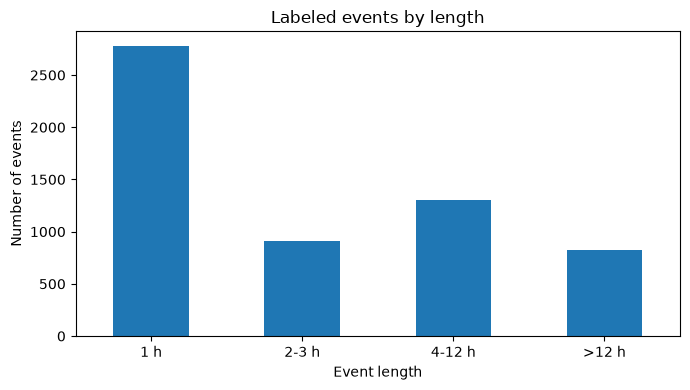

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
events["length_group"].value_counts().reindex(LENGTH_LABELS).plot(kind="bar", ax=ax)
ax.set_xlabel("Event length")
ax.set_ylabel("Number of events")
ax.set_title("Labeled events by length")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "lead_events_by_length.png", dpi=200)
plt.show()

## 8. Save the results

In [16]:
labels_out = g[["building_id", "timestamp", "label"] + label_cols + ["in_lead", "in_zero_run"]]
try:
    labels_out.to_parquet(OUT_DIR / "lead_labels.parquet", index=False)
    print("saved lead_labels.parquet")
except Exception as e:
    print("parquet not available (", type(e).__name__, "), saving csv.gz instead")
    labels_out.to_csv(OUT_DIR / "lead_labels.csv.gz", index=False)

pd.Series(sorted(labeled_buildings), name="building_id").to_csv(OUT_DIR / "labeled_building_ids.csv", index=False)
lab_meta.to_csv(OUT_DIR / "labeled_buildings_info.csv", index=False)
events.to_csv(OUT_DIR / "lead_events.csv", index=False)
n_all.to_csv(OUT_DIR / "table_events_all.csv")
h_all.to_csv(OUT_DIR / "table_hours_all.csv")
n_edu.to_csv(OUT_DIR / "table_events_education.csv")
h_edu.to_csv(OUT_DIR / "table_hours_education.csv")
n_use.to_csv(OUT_DIR / "table_events_usable.csv")
print("saved events and count tables to", OUT_DIR.resolve())

saved lead_labels.parquet
saved events and count tables to /Users/barnnitashrestha/DSAI/CP-LAB/Project/outputs


## 9. What to decide and write down

**What the real files showed (run on 18 October)**

- **LEAD file size.** The labeled file covers **200 buildings**: 1,749,494 rows, **37,296 labeled hours** (2.13% of rows) and **5,811 events** (5,716 usable after removing events mostly inside zero runs). The LEAD paper describes 1,413 labeled meters, and `test_features.csv` holds 206 other buildings with no labels. Check the authors' repository for fuller labels. Until then, say "200 labeled buildings" in the report.
- **How the labels were made.** By hand: annotators looked at plots in roughly 24-hour windows and marked point and sequence anomalies (LEAD 1.0 paper). So "agreement" means recovering what a person sees as unusual. It is not a confirmed fault.
- **The 200 labeled buildings.** 80 are Education, 62 Office, 23 Entertainment/public assembly, 13 Lodging/residential and 22 are of other types. They come from 14 of the 16 sites.
- **Events by length (all labeled buildings).** 2,780 of 1 h, 906 of 2-3 h, 1,302 of 4-12 h, 823 of over 12 h (longest 167 h). Every length group has at least 98 test events (at least 30 for Education only), so no group needs to be merged.
- **Readings did not match at first (90.4%), and this is explained.** (1) GEPIII stores site 0 in kBTU and LEAD in kWh (factor 0.2931). After converting, 98.96% of directly compared rows match. (2) 6.15% of LEAD rows have a blank reading where GEPIII has one; none of them is labeled anomalous. (3) 17,031 labeled hours have a LEAD reading of exactly 1.0 that GEPIII does not show; the reason is not known.
- **Consequences.** Use GEPIII readings for modeling and only the labels from LEAD. Use kWh everywhere, including site 0. Evaluate only on the labeled buildings. In the first run, which used all 1,413 GEPIII buildings, zero runs of 24 hours or more affected 3.89% of rows, and 2,222 labeled hours fell in them. This version counts them for the labeled buildings only, so the figures will differ.

**To write in the report**

- Unlabeled hours inside the labeled buildings are treated as normal. Buildings outside the labeled file are not used for evaluation.
- The zero-run length used and how many hours it affects.
- The rule for removing zero-run events (here: more than half the hours in a zero run).
- Education results are shown next to all-buildings results.
- LEAD 1.0 comes from the same source as GEPIII, so it is not an independent check.

To use the labels in your pipeline, merge `lead_labels` into your hourly table on `building_id` and `timestamp`, and restrict the evaluation to `labeled_building_ids.csv`.

In [17]:
free_memory("Part A done")

[memory freed] Part A done | elapsed 0.1 min


# Data checks and exploration (labeled buildings)

**What happens:** the electricity readings (meter 0) of the labeled buildings are read, and the usual checks are run: duplicates, negative values and empty readings. Daily and weekly patterns are plotted. A last check shows why history features must be built by **time** and not by row position.

**Why it matters:** the plots show that use depends strongly on the hour and the day of the week, which is why the predictors use calendar features. The row-position check explains why Part B builds a complete hourly table first.

In [18]:
ids = pd.read_csv(OUT_DIR / "labeled_building_ids.csv")["building_id"].astype(int).tolist()
id_set = set(ids)

parts_ = []
for chunk in pd.read_csv(GEPIII_TRAIN, usecols=["building_id", "meter", "timestamp", "meter_reading"],
                         dtype={"building_id": "int32", "meter": "int8", "meter_reading": "float32"},
                         chunksize=2_000_000):
    parts_.append(chunk[(chunk["meter"] == 0) & chunk["building_id"].isin(id_set)].drop(columns="meter"))
eda = pd.concat(parts_, ignore_index=True)
del parts_
eda["timestamp"] = pd.to_datetime(eda["timestamp"])

meta_ = pd.read_csv(GEPIII_META)
eda = eda.merge(meta_[["building_id", "site_id", "primary_use"]], on="building_id", how="left")
if CONVERT_SITE0_TO_KWH:
    is0 = eda["site_id"].eq(0)
    eda.loc[is0, "meter_reading"] = (eda.loc[is0, "meter_reading"] * KBTU_TO_KWH).astype("float32")

checks = {
    "buildings": int(eda["building_id"].nunique()),
    "rows": int(len(eda)),
    "exact duplicate rows": int(eda.duplicated().sum()),
    "duplicate building-timestamp rows": int(eda.duplicated(["building_id", "timestamp"]).sum()),
    "negative readings": int((eda["meter_reading"] < 0).sum()),
    "missing readings": int(eda["meter_reading"].isna().sum()),
    "exact zero readings": int((eda["meter_reading"] == 0).sum()),
    "share of exact zeros (%)": round(float((eda["meter_reading"] == 0).mean() * 100), 2),
}
for k, v in checks.items():
    print(f"{k:38s} {v}")

buildings                              200
rows                                   1749494
exact duplicate rows                   0
duplicate building-timestamp rows      0
negative readings                      0
missing readings                       0
exact zero readings                    70157
share of exact zeros (%)               4.01


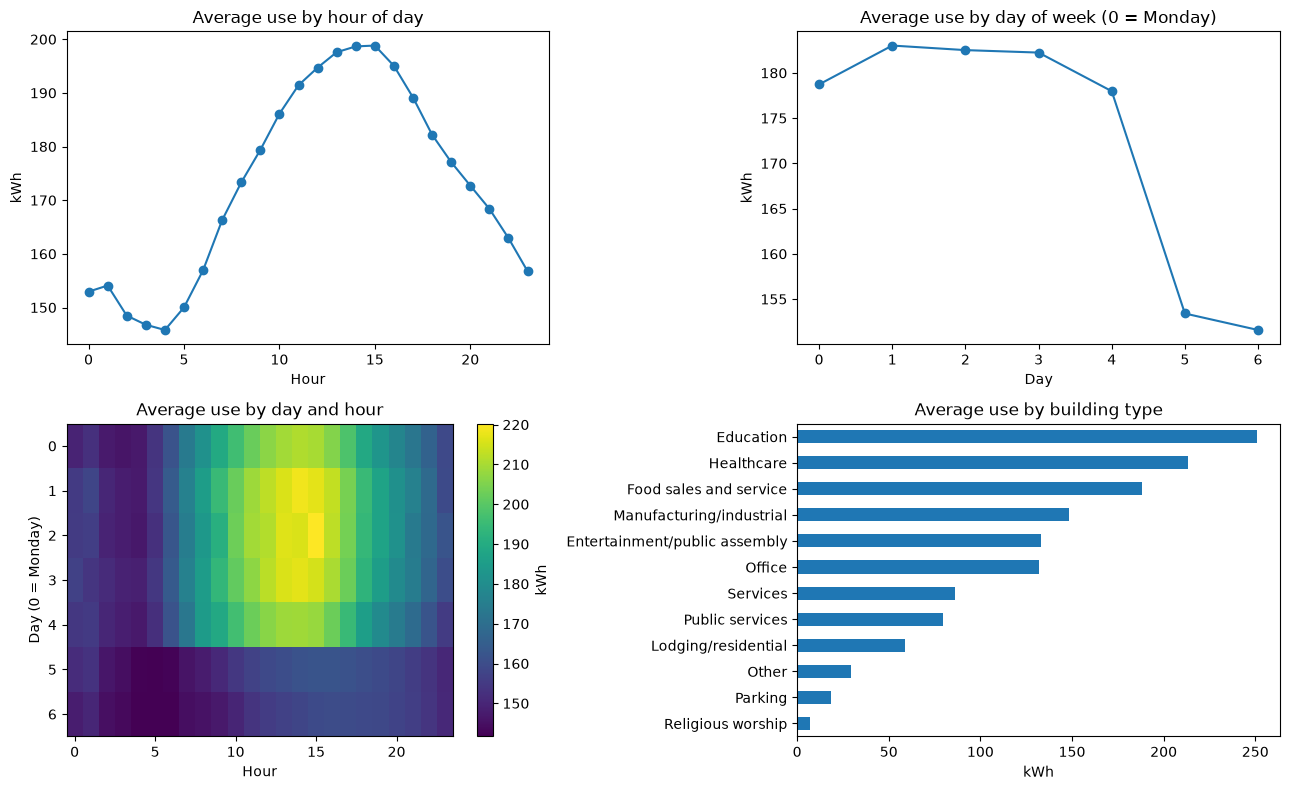

In [19]:
eda = eda.drop_duplicates(["building_id", "timestamp"])
eda = eda[eda["meter_reading"].notna() & (eda["meter_reading"] >= 0)].copy()
eda["hour"] = eda["timestamp"].dt.hour
eda["dow"] = eda["timestamp"].dt.dayofweek

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
eda.groupby("hour")["meter_reading"].mean().plot(ax=ax[0, 0], marker="o")
ax[0, 0].set(title="Average use by hour of day", xlabel="Hour", ylabel="kWh")
eda.groupby("dow")["meter_reading"].mean().plot(ax=ax[0, 1], marker="o")
ax[0, 1].set(title="Average use by day of week (0 = Monday)", xlabel="Day", ylabel="kWh")
heat = eda.pivot_table(values="meter_reading", index="dow", columns="hour", aggfunc="mean")
im = ax[1, 0].imshow(heat, aspect="auto")
ax[1, 0].set(title="Average use by day and hour", xlabel="Hour", ylabel="Day (0 = Monday)")
fig.colorbar(im, ax=ax[1, 0], label="kWh")
eda.groupby("primary_use")["meter_reading"].mean().sort_values().plot.barh(ax=ax[1, 1])
ax[1, 1].set(title="Average use by building type", xlabel="kWh", ylabel="")
plt.tight_layout()
plt.savefig(OUT_DIR / "eda_profiles.png", dpi=200, bbox_inches="tight")
plt.show()

### Why history must be built by time

Hourly data should have one row per building per hour, but some hours are missing. If a lag feature is built by shifting rows ("24 rows back"), then wherever hours are missing the shift reaches back more than 24 hours. The cell below measures how often that happens in these data. Part B avoids the problem by building a complete hourly table first.

In [20]:
e2 = eda[["building_id", "timestamp", "meter_reading"]].sort_values(["building_id", "timestamp"]).reset_index(drop=True)
gap = e2.groupby("building_id")["timestamp"].diff()
share_gap = float((gap.dropna() != pd.Timedelta(hours=1)).mean() * 100)
print(f"consecutive rows that are NOT exactly 1 hour apart: {share_gap:.3f}%")

e2["row_lag_24"] = e2.groupby("building_id")["meter_reading"].shift(24)
look = e2[["building_id", "timestamp", "meter_reading"]].copy()
look["timestamp"] = look["timestamp"] + pd.Timedelta(hours=24)
look = look.rename(columns={"meter_reading": "time_lag_24"})
e2 = e2.merge(look, on=["building_id", "timestamp"], how="left")
valid = e2["row_lag_24"].notna()
wrong = valid & ~np.isclose(e2["row_lag_24"], e2["time_lag_24"], equal_nan=True)
share_wrong = float(wrong.sum() / valid.sum() * 100)
print(f"row-based lag_24 is NOT the reading 24 hours earlier in {share_wrong:.2f}% of rows")

checks["rows not exactly 1 h after the previous row (%)"] = round(share_gap, 3)
checks["row-based lag_24 wrong (%)"] = round(share_wrong, 2)
pd.Series(checks, name="value").to_csv(OUT_DIR / "table_data_checks.csv", header=True)
print("saved table_data_checks.csv")

consecutive rows that are NOT exactly 1 hour apart: 0.074%
row-based lag_24 is NOT the reading 24 hours earlier in 0.89% of rows
saved table_data_checks.csv


In [21]:
free_memory("Data checks done")

[memory freed] Data checks done | elapsed 0.2 min


# Part B: Predictors (expected consumption)

**What this notebook does, in order**
1. Loads the raw electricity readings for the 200 labeled buildings, converts to kWh, and builds a complete hourly table (every building, every hour of 2016).
2. Marks long runs of zeros as missing (the same rule as Part A).
3. Adds weather (carried forward only, never backward).
4. Builds features: calendar, building facts, weather, and **history** (same hour yesterday, same hour last week, previous hour). History is taken from the hourly table by time, and a check confirms it.
5. Builds the two simple predictors: **same as last hour** and **historical typical value**.
6. Trains one tree model on three feature sets: **A** (no history), **B** (adds yesterday and last week), **C** (adds the previous hour). All three use identical settings and the same training rows.
7. Saves the predictions and an accuracy table.

**What this notebook does not do:** it does not use labels, and it does not flag anything. Flagging is Part C.

**Fairness rules built in**
- The split is by time: train before 2016-09-13, validation until 2016-11-07, test after. The month is not used as a feature, because training covers only January to September.
- Everything learned (typical values, model) comes from the training period. Settings are chosen on validation only.
- All models train on the same rows, those where all history values exist, so A, B and C differ only in the features they see.
- A model's prediction is left empty on hours where its own history is missing. Part C then compares predictors on exactly the same hours.

Run the cells in order. Cells marked **CHANGE** may need your paths. Expect roughly 10 to 20 minutes in total on a laptop; the tuning step is the slow part and can be switched off.

> **Model settings are pinned in this notebook.** `TUNE = False` and the settings below are the ones the earlier tuning run chose (600 iterations, learning rate 0.05, 127 leaves, 100 samples per leaf, L2 1.0), so a re-run gives the same predictors without repeating the search. Set `TUNE = True` in the Part B settings to repeat the search on validation.

## 0. Settings for this part

The shared paths, dates and rules are in the master settings cell at the top of the notebook. Only settings specific to this part are here.

In [22]:
from pathlib import Path
import json, time
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

# ---- paths (relative to the folder this notebook is in) ----
LABELED_IDS  = str(OUT_DIR / "labeled_building_ids.csv")     # from Part A

# ---- time split (same as Parts A, C, D) ----

# ---- data rules ----

# ---- model settings ----
TUNE = False                    # try a few settings on validation and keep the best (set False to save time)
TUNE_SAMPLE = 0.3              # share of training rows used while tuning
DEFAULT_PARAMS = dict(max_iter=600, learning_rate=0.05, max_leaf_nodes=127, min_samples_leaf=100, l2_regularization=1.0)
CANDIDATES = [
    dict(max_iter=200, learning_rate=0.1,  max_leaf_nodes=31,  min_samples_leaf=50, l2_regularization=0.0),
    dict(max_iter=400, learning_rate=0.1,  max_leaf_nodes=63,  min_samples_leaf=50, l2_regularization=0.0),
    dict(max_iter=600, learning_rate=0.05, max_leaf_nodes=127, min_samples_leaf=100, l2_regularization=1.0),
]
SEED = 0

## 1. Load the readings and build the hourly table

**What happens:** only electricity (meter 0) for the 200 labeled buildings is read, in chunks to save memory. Site 0 is converted from kBTU to kWh. Then a complete table is built: every building crossed with every hour of 2016. Hours with no reading become empty values, and are never invented.

**What to check:** 200 buildings, 8,784 hours each, 1,756,800 rows, and a small share of empty readings.

In [23]:
ids = pd.read_csv(LABELED_IDS)["building_id"].astype(int).tolist()
id_set = set(ids)

parts = []
for chunk in pd.read_csv(GEPIII_TRAIN, usecols=["building_id", "meter", "timestamp", "meter_reading"],
                         dtype={"building_id": "int32", "meter": "int8", "meter_reading": "float32"},
                         chunksize=2_000_000):
    chunk = chunk[(chunk["meter"] == 0) & chunk["building_id"].isin(id_set)]
    parts.append(chunk.drop(columns="meter"))
raw = pd.concat(parts, ignore_index=True)
raw["timestamp"] = pd.to_datetime(raw["timestamp"])
raw = raw.drop_duplicates(["building_id", "timestamp"])

meta = pd.read_csv(GEPIII_META)
meta = meta[meta["building_id"].isin(id_set)].copy()
raw = raw.merge(meta[["building_id", "site_id"]], on="building_id", how="left")
if CONVERT_SITE0_TO_KWH:
    is0 = raw["site_id"].eq(0)
    raw.loc[is0, "meter_reading"] = (raw.loc[is0, "meter_reading"] * KBTU_TO_KWH).astype("float32")
    print("converted", int(is0.sum()), "rows at site 0 from kBTU to kWh")

hours = pd.date_range(GRID_START, GRID_END, freq="h")
grid = pd.MultiIndex.from_product([sorted(id_set), hours], names=["building_id", "timestamp"]).to_frame(index=False)
df = grid.merge(raw[["building_id", "timestamp", "meter_reading"]], on=["building_id", "timestamp"], how="left")
df = df.sort_values(["building_id", "timestamp"]).reset_index(drop=True)

print("buildings:", df["building_id"].nunique(), "| hours per building:", df.groupby("building_id").size().unique())
print("rows:", len(df), "| empty readings:", int(df["meter_reading"].isna().sum()),
      f"({df['meter_reading'].isna().mean()*100:.2f}%)")

converted 70272 rows at site 0 from kBTU to kWh
buildings: 200 | hours per building: [8784]
rows: 1756800 | empty readings: 7306 (0.42%)


## 2. Mark long zero runs as missing

**What happens:** a run of exact zeros lasting `ZERO_RUN_HOURS` hours or more is treated as missing (a meter or data problem, not real low use). This is the same rule as Part A, so the hours match. The cleaned reading `y` is used for training and history; the original reading is kept for the output file.

In [24]:
z = df["meter_reading"].eq(0)
change = (z != z.shift()) | (df["building_id"] != df["building_id"].shift())
run_id = change.cumsum()
run_len = z.groupby(run_id).transform("size")
df["in_zero_run"] = z & (run_len >= ZERO_RUN_HOURS)
df["y"] = df["meter_reading"].where(~df["in_zero_run"])

print("hours in zero runs:", int(df["in_zero_run"].sum()), f"({df['in_zero_run'].mean()*100:.2f}% of rows)")
print("usable readings (not empty, not in a zero run):", int(df["y"].notna().sum()))

hours in zero runs: 54095 (3.08% of rows)
usable readings (not empty, not in a zero run): 1695399


### Look at the zero-run rule

The building with the most removed hours, raw reading against the cleaned reading. Look at this plot (and a few other buildings) and decide whether 24 hours is a sensible limit.

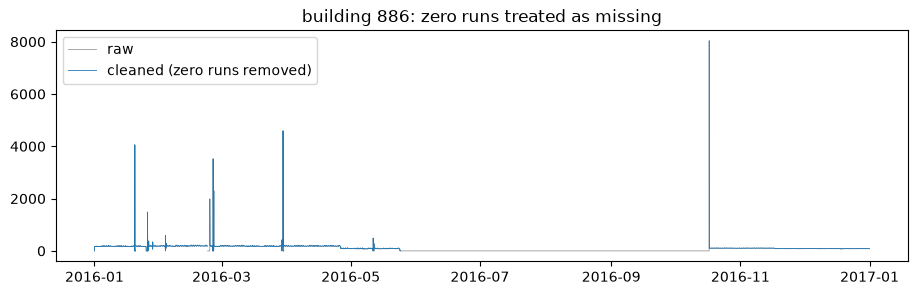

In [25]:
if df["in_zero_run"].any():
    b = df.loc[df["in_zero_run"], "building_id"].value_counts().index[0]
    s = df[df["building_id"] == b]
    plt.figure(figsize=(11, 3))
    plt.plot(s["timestamp"], s["meter_reading"], linewidth=0.6, color="0.6", label="raw")
    plt.plot(s["timestamp"], s["y"], linewidth=0.6, label="cleaned (zero runs removed)")
    plt.title(f"building {b}: zero runs treated as missing")
    plt.legend()
    plt.savefig(OUT_DIR / "zero_run_example.png", dpi=200, bbox_inches="tight")
    plt.show()

## 3. Add weather and building facts

**What happens:** weather is placed on the hourly grid for each site and carried **forward only**. A missing value is filled with the last known earlier value, never a later one, so no future information leaks backward. Values still missing at the very start stay empty (the model handles empty values). Building facts are joined by building.

The calendar month is deliberately not used.

In [26]:
wcols = ["air_temperature", "dew_temperature", "cloud_coverage", "precip_depth_1_hr", "sea_level_pressure", "wind_speed"]
w = pd.read_csv(GEPIII_WEATHER, usecols=["site_id", "timestamp"] + wcols, parse_dates=["timestamp"])
sites = sorted(meta["site_id"].unique())
w = w[w["site_id"].isin(sites)].drop_duplicates(["site_id", "timestamp"])
wgrid = pd.MultiIndex.from_product([sites, hours], names=["site_id", "timestamp"])
w = w.set_index(["site_id", "timestamp"]).reindex(wgrid)
w = w.groupby(level="site_id").ffill().reset_index()          # forward fill only

df = df.merge(meta[["building_id", "site_id", "primary_use", "square_feet", "year_built", "floor_count"]],
              on="building_id", how="left").merge(w, on=["site_id", "timestamp"], how="left")

use_codes = {u: i for i, u in enumerate(sorted(meta["primary_use"].unique()))}
df["primary_use_code"] = df["primary_use"].map(use_codes)
df["bld_idx"] = df["building_id"].map({b: i for i, b in enumerate(sorted(id_set))})
df["hour"] = df["timestamp"].dt.hour
df["dow"] = df["timestamp"].dt.dayofweek
df["is_weekend"] = (df["dow"] >= 5).astype(int)
df["split"] = np.where(df["timestamp"] < TRAIN_END, "train", np.where(df["timestamp"] < VAL_END, "val", "test"))

print("share still empty per weather column:")
print(df[wcols].isna().mean().round(3).to_string())
print("rows per split:", df["split"].value_counts().to_dict())

share still empty per weather column:
air_temperature       0.000
dew_temperature       0.000
cloud_coverage        0.005
precip_depth_1_hr     0.205
sea_level_pressure    0.120
wind_speed            0.000
rows per split: {'train': 1228800, 'val': 264000, 'test': 264000}


## 4. History features (by time) and a check

**What happens:** the table has exactly one row per building per hour, so a shift of 1, 24 or 168 rows is the reading 1 hour, 1 day or 1 week earlier. History values are on the log scale, `log(1 + kWh)`, built from the cleaned reading, so zero-run hours and missing hours give empty history.

**Check:** the notebook looks the history up again by time (timestamp minus 24 hours) and compares. All values must match. If not, stop and fix before going on.

In [27]:
df["ly"] = np.log1p(df["y"])
g = df.groupby("building_id")["ly"]
df["lag_1"] = g.shift(1)
df["lag_24"] = g.shift(24)
df["lag_168"] = g.shift(168)

# check: look up the reading 24 h and 168 h earlier by timestamp and compare
look = df[["building_id", "timestamp", "ly"]].copy()
for k in (24, 168):
    shifted = look.assign(timestamp=look["timestamp"] + pd.Timedelta(hours=k)).rename(columns={"ly": f"chk_{k}"})
    m = df[["building_id", "timestamp", f"lag_{k}"]].merge(shifted[["building_id", "timestamp", f"chk_{k}"]],
                                                           on=["building_id", "timestamp"], how="left")
    same = np.isclose(m[f"lag_{k}"], m[f"chk_{k}"], equal_nan=True)
    print(f"lag_{k}: matches the time-based lookup on {same.mean()*100:.3f}% of rows")
    assert same.all(), f"lag_{k} does not match a time-based lookup"

df["common"] = df[["lag_1", "lag_24", "lag_168"]].notna().all(axis=1) & df["y"].notna()
print()
print("rows with all history present and a usable reading, per split:")
print(df[df["common"]].groupby("split").size().reindex(["train", "val", "test"]).to_string())

lag_24: matches the time-based lookup on 100.000% of rows
lag_168: matches the time-based lookup on 100.000% of rows

rows with all history present and a usable reading, per split:
split
train    1135206
val       249407
test      257993


## 5. The two simple predictors

**Same as last hour.** The prediction for an hour is the previous hour's reading (kWh). It needs no training and sets the bar that any model has to beat. It is empty where the previous hour is missing.

**Historical typical value.** The median reading for the same building, same hour of day, and weekday-or-weekend, using the **training period only**. If a combination has no data it falls back to the building and hour, then to the building.

In [28]:
df["pred_last_hour"] = df.groupby("building_id")["y"].shift(1)

tr = df[(df["split"] == "train") & df["y"].notna()]
med3 = tr.groupby(["building_id", "hour", "is_weekend"])["y"].median().rename("m3")
med2 = tr.groupby(["building_id", "hour"])["y"].median().rename("m2")
med1 = tr.groupby("building_id")["y"].median().rename("m1")
df = (df.merge(med3, left_on=["building_id", "hour", "is_weekend"], right_index=True, how="left")
        .merge(med2, left_on=["building_id", "hour"], right_index=True, how="left")
        .merge(med1, left_on="building_id", right_index=True, how="left"))
df["pred_typical"] = df["m3"].fillna(df["m2"]).fillna(df["m1"])
df = df.drop(columns=["m3", "m2", "m1"])
df = df.sort_values(["building_id", "timestamp"]).reset_index(drop=True)

print("empty same-as-last-hour predictions:", int(df["pred_last_hour"].isna().sum()))
print("empty typical-value predictions:", int(df["pred_typical"].isna().sum()))

empty same-as-last-hour predictions: 61598
empty typical-value predictions: 0


## 6. The model: feature sets A, B and C

**What happens:** one tree model (histogram gradient boosting) is trained on the log of the reading. Three feature sets are used:
- **A:** calendar, building facts, weather (no history),
- **B:** A plus same hour yesterday and same hour last week,
- **C:** B plus the previous hour.

Building and use type are treated as categories. All three models use identical settings and the same training rows (rows where all history exists), so the only difference is what each one is allowed to see.

In [29]:
cal = ["hour", "dow", "is_weekend"]
bld = ["bld_idx", "site_id", "primary_use_code", "square_feet", "year_built", "floor_count"]
cat_cols = ["bld_idx", "site_id", "primary_use_code"]
FEATURES = {
    "A": cal + bld + wcols,
    "B": cal + bld + wcols + ["lag_24", "lag_168"],
    "C": cal + bld + wcols + ["lag_24", "lag_168", "lag_1"],
}
# a feature that is empty for every training row cannot be used (and would stop the model), so drop it
_train = df[df["split"] == "train"]
empty_feats = [c for c in dict.fromkeys(sum(FEATURES.values(), [])) if _train[c].isna().all()]
if empty_feats:
    print("dropping features that are empty in the training period:", empty_feats)
    FEATURES = {k: [c for c in v if c not in empty_feats] for k, v in FEATURES.items()}
for k, v in FEATURES.items():
    print(k, len(v), "features")

train_rows = df[(df["split"] == "train") & df["common"]]
val_rows = df[(df["split"] == "val") & df["common"]]
print("training rows:", len(train_rows), "| validation rows:", len(val_rows))

def make_model(params):
    return HistGradientBoostingRegressor(loss="squared_error", early_stopping=False, random_state=SEED, **params)

def fit(feats, params, rows):
    mask = [c in cat_cols for c in feats]
    m = make_model(params)
    m.set_params(categorical_features=mask)
    m.fit(rows[feats], np.log1p(rows["y"]))
    return m

def rmsle(model, feats, rows):
    p = model.predict(rows[feats])
    return float(np.sqrt(np.mean((p - np.log1p(rows["y"])) ** 2)))

A 15 features
B 17 features
C 18 features
training rows: 1135206 | validation rows: 249407


## 7. Light tuning (validation only, feature set C)

**What happens:** three settings are tried on a sample of the training rows, using set C. The one with the lowest validation error is used for **all three** feature sets. Tuning uses validation only, never test. Set `TUNE = False` to skip this and use the default settings.

In [30]:
if TUNE:
    sample = train_rows.sample(frac=TUNE_SAMPLE, random_state=SEED)
    results = []
    for p in CANDIDATES:
        t0 = time.time()
        m = fit(FEATURES["C"], p, sample)
        e = rmsle(m, FEATURES["C"], val_rows)
        results.append((e, p))
        print(f"validation error {e:.4f} | {p} | {time.time()-t0:.0f}s")
    BEST = min(results, key=lambda r: r[0])[1]
else:
    BEST = DEFAULT_PARAMS
print("\nsettings used for A, B and C:", BEST)


settings used for A, B and C: {'max_iter': 600, 'learning_rate': 0.05, 'max_leaf_nodes': 127, 'min_samples_leaf': 100, 'l2_regularization': 1.0}


## 8. Train A, B and C and predict every hour

**What happens:** each feature set is trained on the full training rows with the chosen settings, then predicts every hour. Predictions are converted back to kWh. A model's prediction is left **empty** where its own history is missing, so Part C compares predictors on identical hours.

In [31]:
models = {}
for name, feats in FEATURES.items():
    t0 = time.time()
    models[name] = fit(feats, BEST, train_rows)
    p = np.expm1(models[name].predict(df[feats])).clip(min=0)
    df["pred_" + name] = p
    print(f"model {name} trained in {time.time()-t0:.0f}s")

df.loc[df[["lag_24", "lag_168"]].isna().any(axis=1), "pred_B"] = np.nan
df.loc[df[["lag_1", "lag_24", "lag_168"]].isna().any(axis=1), "pred_C"] = np.nan
print("empty predictions  A:", int(df["pred_A"].isna().sum()), "| B:", int(df["pred_B"].isna().sum()),
      "| C:", int(df["pred_C"].isna().sum()))

model A trained in 23s
model B trained in 24s
model C trained in 26s
empty predictions  A: 0 | B: 106951 | C: 113160


## 9. Accuracy of the predictors

**What happens:** all five predictors are scored on the same hours (reading usable, every prediction present), for validation and test. Measures: mean absolute error and root mean squared error in kWh, R squared, and the error on the log scale (RMSLE).

**This is a check on the predictors, not the project result.** The project result is how well the flags match the labeled events (Part D). Accuracy and flag quality can disagree.

**What to expect:** the models should beat the typical value, and C should be the most accurate and A the least. If B and C look as good as your old model (R squared about 0.968), that is believable only for C. A and B should score lower, because the old pipeline used information that is not allowed here. If A is as good as C, check for leakage.

In [32]:
pc = ["pred_last_hour", "pred_typical", "pred_A", "pred_B", "pred_C"]
names = {"pred_last_hour": "Same as last hour", "pred_typical": "Historical typical value",
         "pred_A": "Model A (no history)", "pred_B": "Model B (+ yesterday, last week)", "pred_C": "Model C (+ previous hour)"}
rows = []
for sp in ["val", "test"]:
    d = df[(df["split"] == sp) & df["y"].notna() & df[pc].notna().all(axis=1)]
    for c in pc:
        err = d["y"] - d[c]
        ss_res = float((err ** 2).sum())
        ss_tot = float(((d["y"] - d["y"].mean()) ** 2).sum())
        rows.append({"split": sp, "predictor": names[c], "hours": len(d),
                     "MAE_kWh": err.abs().mean(), "RMSE_kWh": np.sqrt((err ** 2).mean()),
                     "R2": 1 - ss_res / ss_tot,
                     "RMSLE": np.sqrt(((np.log1p(d["y"]) - np.log1p(d[c].clip(lower=0))) ** 2).mean())})
acc = pd.DataFrame(rows)
acc.round({"MAE_kWh": 2, "RMSE_kWh": 2, "R2": 3, "RMSLE": 3}).to_csv(OUT_DIR / "predictor_accuracy.csv", index=False)
print(acc.round({"MAE_kWh": 2, "RMSE_kWh": 2, "R2": 3, "RMSLE": 3}).to_string(index=False))

split                        predictor  hours  MAE_kWh  RMSE_kWh    R2  RMSLE
  val                Same as last hour 249407     9.10     49.09 0.984  0.234
  val         Historical typical value 249407    23.18     65.28 0.971  0.753
  val             Model A (no history) 249407    26.03     67.90 0.969  0.698
  val Model B (+ yesterday, last week) 249407    16.41     55.92 0.979  0.518
  val        Model C (+ previous hour) 249407     8.21     33.39 0.992  0.178
 test                Same as last hour 257993     8.09     30.45 0.993  0.200
 test         Historical typical value 257993    30.28     77.00 0.958  0.699
 test             Model A (no history) 257993    32.71     79.20 0.955  0.705
 test Model B (+ yesterday, last week) 257993    19.62     55.98 0.978  0.441
 test        Model C (+ previous hour) 257993     8.86     31.94 0.993  0.227


## 10. A quick look at one building

**What happens:** one week of the test period for one building: the reading and three predictors. The figure is saved for the report.

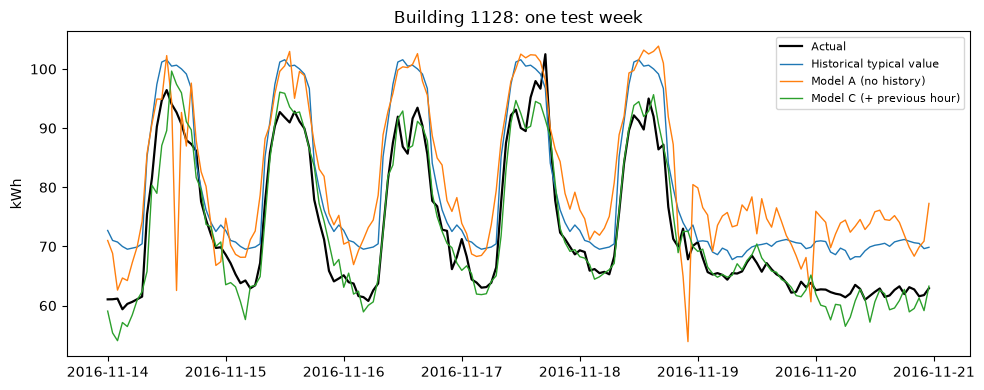

In [33]:
import matplotlib.pyplot as plt

b = df[df["split"] == "test"].groupby("building_id")["y"].mean().sort_values().index[len(id_set) // 2]
wk = df[(df["building_id"] == b) & (df["timestamp"] >= VAL_END + pd.Timedelta(days=7)) &
        (df["timestamp"] < VAL_END + pd.Timedelta(days=14))]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wk["timestamp"], wk["y"], color="black", lw=1.6, label="Actual")
ax.plot(wk["timestamp"], wk["pred_typical"], lw=1, label="Historical typical value")
ax.plot(wk["timestamp"], wk["pred_A"], lw=1, label="Model A (no history)")
ax.plot(wk["timestamp"], wk["pred_C"], lw=1, label="Model C (+ previous hour)")
ax.set_title(f"Building {b}: one test week")
ax.set_ylabel("kWh")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "predictors_example_week.png", dpi=200)
plt.show()

## 11. Save the predictions

**What happens:** the file Part C reads. One row per building and hour with the original reading (kWh) and one column per predictor. Training rows are included (the model predictions there are in-sample), because Part C needs the training readings for the fixed-percentile method. The settings are saved so the run can be reproduced.

In [34]:
out = df[["building_id", "timestamp", "meter_reading", "split"] + pc].copy()
try:
    out.to_parquet(OUT_DIR / "predictions.parquet", index=False)
    print("saved predictions.parquet")
except Exception as e:
    print("parquet not available (", type(e).__name__, "), saving csv.gz instead")
    out.to_csv(OUT_DIR / "predictions.csv.gz", index=False)

with open(OUT_DIR / "predictor_settings.json", "w") as f:
    json.dump({"model_params": BEST, "features": FEATURES, "tuned": TUNE, "seed": SEED,
               "train_end": str(TRAIN_END), "val_end": str(VAL_END), "zero_run_hours": ZERO_RUN_HOURS}, f, indent=2)
print("rows:", len(out), "| columns:", list(out.columns))

saved predictions.parquet
rows: 1756800 | columns: ['building_id', 'timestamp', 'meter_reading', 'split', 'pred_last_hour', 'pred_typical', 'pred_A', 'pred_B', 'pred_C']


## What to write down for the report

- The split dates, and that the month is not used as a feature.
- That history is built by time and verified (the check in step 4).
- That the typical value and the model use training data only, and settings were picked on validation only.
- That A, B and C use identical settings and rows, differing only in features.
- The accuracy table (step 9), with the note that accuracy is not the project result.

**Next:** run Part C (cut-offs and flags), then Part D (evaluation). Part C reads `outputs/predictions.parquet` (or `.csv.gz`) and needs no changes if you keep the column names.

In [35]:
free_memory("Part B done")

[memory freed] Part B done | elapsed 1.5 min


# Part C: Cut-offs and flags

**What this notebook does, in order**
1. Loads the saved predictions (from the predictors notebook) and the labels (from Part A). Keeps only the 200 labeled buildings.
2. Measures each predictor's error on every hour.
3. Learns each building's normal error from the validation period only, with labeled anomaly hours left out.
4. Scores every hour: how unusual is this error for this building?
5. Picks one cut-off per predictor so that all predictors raise the same false-alarm rate on normal validation hours.
6. Builds the comparison method: a fixed percentile of each building's own training use.
7. **Freezes** everything to files. Nothing is changed after this point.
8. Reloads the frozen files and produces flags for validation and test.
9. Checks that the flag rates on normal validation hours are close to the target.

**Why the cut-offs are frozen first:** if cut-offs were adjusted after looking at test results, the test results would no longer be an honest check. The notebook reloads the saved files in step 8 on purpose, so the flags can only come from the frozen values.

**Do not report flag rates as findings.** They are set by the cut-off, not by how good a predictor is. The real comparison happens in the evaluation notebook (Part D).

Run the cells in order and read each printed result before moving on. Cells marked **CHANGE** may need your file or column names.

## 0. Settings for this part

The shared paths, dates and rules are in the master settings cell at the top of the notebook. Only settings specific to this part are here.

Paths are relative to the folder this notebook is in. The predictions file must have one row per building and hour, with the real reading and one prediction column per predictor. Save predictions in the **same unit as the reading (kWh)**, even if the model was trained on log values. The notebook takes the log itself.

In [36]:
from pathlib import Path
import json, datetime
import numpy as np
import pandas as pd

# ---- input files ----
PRED_FILE  = str(OUT_DIR / "predictions.parquet")        # from the predictors notebook (csv, csv.gz or parquet)
LABEL_FILE = str(OUT_DIR / "lead_labels.parquet")        # from Part A (falls back to the csv.gz version)
INFO_FILE  = str(OUT_DIR / "labeled_buildings_info.csv") # from Part A

# ---- column names in the predictions file (CHANGE) ----
ID_COL, TIME_COL, ACTUAL_COL = "building_id", "timestamp", "meter_reading"
# name used in this notebook : column in your predictions file
PRED_COLS = {
    "last_hour": "pred_last_hour",   # same as last hour
    "typical":   "pred_typical",     # historical typical value
    "A":         "pred_A",           # model, no history
    "B":         "pred_B",           # model, adds yesterday and last week
    "C":         "pred_C",           # model, adds previous hour
}

# ---- rules ----
USE_LOG = True                  # measure errors on log(1 + kWh)
TARGET_FALSE_ALARM = 0.005      # share of normal validation hours that may be flagged (0.5%)
MAD_FLOOR = 0.05                # smallest allowed building variation (in log units; a share of the building level if USE_LOG is False)
MIN_VAL_HOURS = 500             # buildings with fewer clean validation hours borrow values from similar buildings
FIXED_PERCENTILE = 100 * (1 - TARGET_FALSE_ALARM)   # comparison method: flag use above this percentile of the building's training use

# ---- split dates (same as the project plan) ----

NAMES = list(PRED_COLS)
print("Predictors:", NAMES)

Predictors: ['last_hour', 'typical', 'A', 'B', 'C']


## 1. Load predictions and labels

**What happens:** the predictions are joined to the labels on building and time. Only the 200 labeled buildings are kept, because the other buildings have no labels and cannot be judged. Hours with no label inside a labeled building are treated as normal. Each hour gets a split (train, val, test) from its date.

**What to check:** the number of buildings should be about 200 and every split should have rows.

In [37]:
def read_any(path):
    """Read parquet, csv or csv.gz. If the named file is missing, try the other formats with the same name."""
    p = Path(path)
    stem = p.name.split(".")[0]
    candidates = [p, p.with_name(stem + ".csv.gz"), p.with_name(stem + ".csv"), p.with_name(stem + ".parquet")]
    for c in candidates:
        if c.exists():
            print("reading", c)
            return pd.read_parquet(c) if c.suffix == ".parquet" else pd.read_csv(c)
    raise FileNotFoundError(f"Could not find {path} (also tried csv.gz, csv, parquet). Check the folder and the name.")


pred = read_any(PRED_FILE)
need = [ID_COL, TIME_COL, ACTUAL_COL] + list(PRED_COLS.values())
missing = [c for c in need if c not in pred.columns]
if missing:
    raise ValueError(f"These columns are not in the predictions file: {missing}. Edit the settings cell. Columns found: {list(pred.columns)}")

pred = pred[need].rename(columns={ID_COL: "building_id", TIME_COL: "timestamp", ACTUAL_COL: "actual",
                                  **{v: "pred_" + k for k, v in PRED_COLS.items()}})
pred["timestamp"] = pd.to_datetime(pred["timestamp"])

labels = read_any(LABEL_FILE)[["building_id", "timestamp", "label", "in_zero_run"]]
labels["timestamp"] = pd.to_datetime(labels["timestamp"])
info = pd.read_csv(INFO_FILE)[["building_id", "site_id", "primary_use"]]

pred = pred[pred["building_id"].isin(set(info["building_id"]))]
df = (pred.merge(labels, on=["building_id", "timestamp"], how="left")
          .merge(info, on="building_id", how="left"))
df["label"] = df["label"].fillna(0).astype(int)
df["in_zero_run"] = df["in_zero_run"].fillna(False).astype(bool)
df["split"] = np.where(df["timestamp"] < TRAIN_END, "train",
                np.where(df["timestamp"] < VAL_END, "val", "test"))

print("buildings:", df["building_id"].nunique())
print("rows per split:")
print(df["split"].value_counts().reindex(["train", "val", "test"]).to_string())
print("labeled anomaly hours per split:")
print(df.groupby("split")["label"].sum().reindex(["train", "val", "test"]).to_string())

reading outputs/predictions.parquet
reading outputs/lead_labels.parquet
buildings: 200
rows per split:
split
train    1228800
val       264000
test      264000
labeled anomaly hours per split:
split
train    27274
val       4826
test      5196


## 2. Measure each predictor's error

**What happens:** for each predictor, error = log(1 + actual) minus log(1 + prediction). Positive means the building used more than expected. Negative values are clipped to zero before the log.

**Which hours count (the "valid" hours):**
- the reading is present,
- the hour is not inside a long run of zeros (treated as missing in Part A),
- **every** predictor has a prediction for that hour. This keeps all predictors on exactly the same hours, so they can be compared fairly.

Hours that are not valid are kept in the table but never flagged.

In [38]:
def tf(x):
    x = np.clip(x, 0, None)
    return np.log1p(x) if USE_LOG else x

pred_cols = ["pred_" + n for n in NAMES]
df["valid"] = df["actual"].notna() & ~df["in_zero_run"] & df[pred_cols].notna().all(axis=1)

for n in NAMES:
    df["err_" + n] = tf(df["actual"]) - tf(df["pred_" + n])

summary = df.groupby("split")["valid"].agg(valid="sum", total="size")
summary["share_valid"] = (summary["valid"] / summary["total"]).round(3)
print(summary.reindex(["train", "val", "test"]).to_string())
print()
print("Mean error per predictor on valid validation hours (should be close to 0):")
print(df[(df["split"] == "val") & df["valid"]][["err_" + n for n in NAMES]].mean().round(3).to_string())

         valid    total  share_valid
split                               
train  1135206  1228800        0.924
val     249407   264000        0.945
test    257993   264000        0.977

Mean error per predictor on valid validation hours (should be close to 0):
err_last_hour   -0.001
err_typical     -0.089
err_A           -0.024
err_B           -0.003
err_C           -0.002


## 3. Learn each building's normal error (validation only)

**What happens:** for each building and predictor, two numbers are learned from **clean validation hours** (valid, and not labeled as an anomaly):
- the **typical error** (median of the errors),
- the **normal variation** (median absolute deviation times 1.4826, which is comparable to a standard deviation but not thrown off by rare extremes).

The variation has a **floor** so a building with almost constant use does not get enormous scores from tiny wobbles.

**Small-history buildings:** a building with fewer than `MIN_VAL_HOURS` clean validation hours borrows both numbers from buildings of the same site and use type (then the same site, then all buildings).

Labeled anomaly hours are left out here only so that anomalies do not widen what counts as normal.

In [39]:
clean_val = df[(df["split"] == "val") & df["valid"] & (df["label"] == 0)]
all_ids = pd.Index(sorted(df["building_id"].unique()), name="building_id")

def mad_scaled(s):
    return (s - s.median()).abs().median() * 1.4826

stats = pd.DataFrame(index=all_ids)
stats["n_clean_val_hours"] = clean_val.groupby("building_id").size().reindex(all_ids).fillna(0).astype(int)
level = tf(clean_val["actual"]).groupby(clean_val["building_id"]).median().reindex(all_ids)
floor = MAD_FLOOR if USE_LOG else MAD_FLOOR * level.clip(lower=1e-6)

for n in NAMES:
    g = clean_val.groupby("building_id")["err_" + n]
    stats["med_" + n] = g.median().reindex(all_ids)
    stats["scale_" + n] = np.maximum(g.apply(mad_scaled).reindex(all_ids), floor)

stats = stats.join(info.set_index("building_id")[["site_id", "primary_use"]])
stats["borrowed"] = stats["n_clean_val_hours"] < MIN_VAL_HOURS

enough = stats[~stats["borrowed"]]
if len(enough) == 0:
    raise ValueError("No building has enough clean validation hours. Lower MIN_VAL_HOURS or check the split dates.")

for col in [c for c in stats.columns if c.startswith(("med_", "scale_"))]:
    by_group = enough.groupby(["site_id", "primary_use"])[col].median()
    by_site = enough.groupby("site_id")[col].median()
    key = pd.MultiIndex.from_frame(stats[["site_id", "primary_use"]])
    fill = pd.Series(by_group.reindex(key).values, index=stats.index)
    fill = fill.fillna(stats["site_id"].map(by_site)).fillna(enough[col].median())
    stats.loc[stats["borrowed"], col] = fill[stats["borrowed"]]

print("buildings with their own values:", int((~stats["borrowed"]).sum()))
print("buildings borrowing values:", int(stats["borrowed"].sum()))
print()
print("Typical normal variation (scale) across buildings, per predictor:")
print(stats[["scale_" + n for n in NAMES]].describe().loc[["min", "50%", "max"]].round(3).to_string())

buildings with their own values: 196
buildings borrowing values: 4

Typical normal variation (scale) across buildings, per predictor:
     scale_last_hour  scale_typical  scale_A  scale_B  scale_C
min            0.050          0.050    0.050    0.050    0.050
50%            0.052          0.092    0.135    0.085    0.052
max            0.277          1.129    1.192    0.786    0.349


## 4. Score every hour

**What happens:** score = |error minus the building's typical error| divided by the building's normal variation. A score of 3 means "this hour's error is about three normal-sized wobbles away from what is usual for this building." The same scoring function is used again in step 8 on the frozen values.

In [40]:
def add_scores(frame, stats_table):
    """Add score_<name> columns using a table of building values. Invalid hours get NaN."""
    out = frame.merge(stats_table[[c for c in stats_table.columns if c.startswith(("med_", "scale_"))]],
                      left_on="building_id", right_index=True, how="left")
    for n in NAMES:
        s = (out["err_" + n] - out["med_" + n]).abs() / out["scale_" + n]
        out["score_" + n] = s.where(out["valid"])
    return out.drop(columns=[c for c in out.columns if c.startswith(("med_", "scale_"))])

scored_val = add_scores(df[df["split"] == "val"], stats)
cv = scored_val[scored_val["valid"] & (scored_val["label"] == 0)]
print("Score summary on clean validation hours:")
print(cv[["score_" + n for n in NAMES]].describe(percentiles=[.5, .9, .99, .995]).round(2).to_string())

Score summary on clean validation hours:
       score_last_hour  score_typical    score_A    score_B    score_C
count        244690.00      244690.00  244690.00  244690.00  244690.00
mean              1.13           1.78       1.49       1.74       0.95
std               3.08           7.99       5.74       6.71       2.35
min               0.00           0.00       0.00       0.00       0.00
50%               0.52           0.64       0.67       0.66       0.55
90%               2.49           2.05       1.98       2.41       1.90
99%               9.75          36.52      21.72      27.16       6.42
99.5%            13.46          62.44      45.39      52.88       9.64
max             176.84         128.13     124.98     125.24     126.17


## 5. Pick one cut-off per predictor (same false-alarm rate)

**What happens:** for each predictor, the cut-off is the score that only `TARGET_FALSE_ALARM` (0.5%) of clean validation hours exceed. Every predictor therefore raises about the same number of false alarms on normal data, and the comparison later is about **how many real events each one catches at that equal cost**.

Labeled anomaly hours are left out of this step only.

In [41]:
cutoffs = {n: float(np.quantile(cv["score_" + n].dropna(), 1 - TARGET_FALSE_ALARM)) for n in NAMES}
print("Cut-offs (score above this is flagged):")
for n, c in cutoffs.items():
    print(f"  {n:10s} {c:6.2f}")

Cut-offs (score above this is flagged):
  last_hour   13.46
  typical     62.44
  A           45.39
  B           52.88
  C            9.64


## 6. The comparison method: fixed percentile of the building's own use

**What happens:** for each building, take its **training** hours (valid, not labeled as an anomaly) and find the value that `FIXED_PERCENTILE` (99.5%) of them stay below. Later, any hour above that value is flagged. It uses no model, so it shows what a simple rule achieves.

It only flags unusually **high** use, because it looks at the level and not at an error. The percentile is set from the target rate so the comparison starts from a similar false-alarm budget, but its real rate on validation will differ and is shown in step 9.

If the predictions file has no training rows, this step is skipped with a message.

In [42]:
train_clean = df[(df["split"] == "train") & df["actual"].notna() & ~df["in_zero_run"] & (df["label"] == 0)]
if len(train_clean) == 0:
    print("No training rows in the predictions file. The fixed-percentile method is skipped.")
    print("To include it, save the training rows (prediction columns may be empty) in the predictions file, or load the hourly table here.")
    fixed = None
else:
    fixed = (train_clean.groupby("building_id")["actual"].quantile(FIXED_PERCENTILE / 100)
             .reindex(all_ids).rename("fixed_threshold").to_frame())
    print("buildings with a fixed threshold:", int(fixed["fixed_threshold"].notna().sum()), "of", len(fixed))
    print(fixed["fixed_threshold"].describe().round(1).to_string())

buildings with a fixed threshold: 200 of 200
count     200.0
mean      283.7
std       523.9
min         3.2
25%        65.8
50%       161.0
75%       315.2
max      6389.5


## 7. Freeze everything

**What happens:** the building values, the cut-offs and the fixed thresholds are written to files, together with the settings and the time they were saved. **From here on, nothing is recomputed.** If you change a setting, rerun the notebook from the top and treat it as a new version, and do it before looking at any test result.

In [43]:
stats.to_csv(OUT_DIR / "cut_building_values.csv")
if fixed is not None:
    fixed.to_csv(OUT_DIR / "cut_fixed_thresholds.csv")
frozen = {
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "cutoffs": cutoffs,
    "settings": {"USE_LOG": USE_LOG, "TARGET_FALSE_ALARM": TARGET_FALSE_ALARM, "MAD_FLOOR": MAD_FLOOR,
                 "MIN_VAL_HOURS": MIN_VAL_HOURS, "FIXED_PERCENTILE": FIXED_PERCENTILE,
                 "TRAIN_END": str(TRAIN_END), "VAL_END": str(VAL_END), "predictors": NAMES},
}
with open(OUT_DIR / "cutoffs.json", "w") as f:
    json.dump(frozen, f, indent=2)
print("frozen at", frozen["created"])
print("saved: cut_building_values.csv, cutoffs.json" + (", cut_fixed_thresholds.csv" if fixed is not None else ""))

frozen at 2026-10-19T17:20:11
saved: cut_building_values.csv, cutoffs.json, cut_fixed_thresholds.csv


## 8. Produce the flags from the frozen files

**What happens:** the saved files are loaded again (not the variables from above) and used to score and flag every validation and test hour. An hour is flagged when its score is above its predictor's cut-off. The fixed method flags an hour when the reading is above the building's fixed threshold. Hours that are not valid are never flagged.

The output table has one row per building and hour, with the label, the score and the flag for each method. This is the input to the evaluation notebook.

In [44]:
stats_f = pd.read_csv(OUT_DIR / "cut_building_values.csv", index_col="building_id")
with open(OUT_DIR / "cutoffs.json") as f:
    frozen_f = json.load(f)
fixed_path = OUT_DIR / "cut_fixed_thresholds.csv"
fixed_f = pd.read_csv(fixed_path, index_col="building_id") if fixed_path.exists() else None

out = add_scores(df[df["split"].isin(["val", "test"])].copy(), stats_f)
for n in NAMES:
    out["flag_" + n] = out["valid"] & (out["score_" + n] > frozen_f["cutoffs"][n])
if fixed_f is not None:
    thr = out["building_id"].map(fixed_f["fixed_threshold"])
    out["flag_fixed"] = out["valid"] & (out["actual"] > thr)

keep = (["building_id", "timestamp", "split", "label", "valid", "actual"]
        + ["score_" + n for n in NAMES] + ["flag_" + n for n in NAMES]
        + (["flag_fixed"] if fixed_f is not None else []))
flags = out[keep].sort_values(["building_id", "timestamp"]).reset_index(drop=True)

try:
    flags.to_parquet(OUT_DIR / "flags.parquet", index=False)
    print("saved flags.parquet")
except Exception as e:
    print("parquet not available (", type(e).__name__, "), saving csv.gz instead")
    flags.to_csv(OUT_DIR / "flags.csv.gz", index=False)

flag_cols = [c for c in flags.columns if c.startswith("flag_")]
print()
print("Flagged hours per split (counts only, not a result):")
print(flags.groupby("split")[flag_cols].sum().to_string())

saved flags.parquet

Flagged hours per split (counts only, not a result):
       flag_last_hour  flag_typical  flag_A  flag_B  flag_C  flag_fixed
split                                                                  
test             1098           291     353     583    1856        4944
val              1506          1315    1268    1313    1724        2656


## 9. Checks before moving on

**Check 1, flag rate on normal validation hours.** For the model-based predictors this should be very close to the target (0.5%). If one is far off, there is a bug in steps 3 to 5. The fixed method will not match exactly, because it uses a level rule and not an error rule.

**Check 2, order of files.** The cut-off file must be older than the flags file.

**Remember:** these rates are set by the cut-off. They say nothing about which predictor is better.

In [45]:
chk = flags[(flags["split"] == "val") & flags["valid"] & (flags["label"] == 0)]
rates = (chk[flag_cols].mean() * 100).round(3).rename("false_alarm_%")
print(f"Target: {TARGET_FALSE_ALARM*100:.3f}%")
print(rates.to_string())

bad = [c for c in flag_cols if c != "flag_fixed" and abs(chk[c].mean() - TARGET_FALSE_ALARM) > TARGET_FALSE_ALARM * 0.2]
print()
print("Predictors more than 20% away from the target:", bad if bad else "none")

flag_file = OUT_DIR / ("flags.parquet" if (OUT_DIR / "flags.parquet").exists() else "flags.csv.gz")
t_cut = (OUT_DIR / "cutoffs.json").stat().st_mtime
t_flag = flag_file.stat().st_mtime
print("cut-offs saved before flags:", t_cut <= t_flag)

Target: 0.500%
flag_last_hour    0.495
flag_typical      0.499
flag_A            0.500
flag_B            0.500
flag_C            0.500
flag_fixed        1.057

Predictors more than 20% away from the target: none
cut-offs saved before flags: True


## What comes next

The next notebook (Part D, evaluation) takes `flags` together with `lead_events.csv` and measures, per predictor and per event length group:
- event recall (an event counts as found if at least one of its hours is flagged),
- event precision (flagged runs that touch a real event),
- detection delay,
- precision at the top 50 and 100,
- all labeled buildings and Education only.

Files created by this notebook (all in `outputs`): `cut_building_values.csv`, `cutoffs.json`, `cut_fixed_thresholds.csv`, `flags.parquet` (or `flags.csv.gz`).

In [46]:
free_memory("Part C done")

[memory freed] Part C done | elapsed 1.5 min


# Part D: Evaluation of the flags against the labeled events

**What this notebook does, in order**
1. Loads the flags (Part C) and the labeled events (Part A). Keeps the evaluation period (test by default) and events that are usable.
2. For every method, finds the **flagged runs**: consecutive flagged hours in one building.
3. **Event-level results:** was each labeled event found, how fast, how much of it was flagged, and were there flags right after it ended?
4. **Run-level results:** how many flagged runs touch a real event (precision), and how clean is the top of the ranked list (precision at 50 and 100)?
5. Splits everything by **event length group** and by **all labeled buildings vs Education only**.
6. Saves tidy tables and one figure for the report.

**How to read the results**
- All methods were set to the same false-alarm rate on normal *validation* hours (Part C). So the question is: at the same alarm budget, which method finds more real events?
- Unlabeled hours inside the 200 labeled buildings are treated as normal. Some of them may be real anomalies nobody labeled, so **precision may be understated**. Report it as such.
- LEAD labels were made by people looking at plots, and LEAD comes from the same source as GEPIII, so this is a check against human judgment and not against ground truth.
- The intervals shown are Wilson 95% intervals. Events inside one building are related to each other, so the intervals are a little too narrow. Treat small differences between methods as unclear.
- Do not change any setting after looking at test results. If you want to explore, set `EVAL_SPLIT = "val"`.

Run the cells in order. Cells marked **CHANGE** may need your file names.

## 0. Settings for this part

The shared paths, dates and rules are in the master settings cell at the top of the notebook. Only settings specific to this part are here.

In [47]:
from pathlib import Path
import numpy as np
import pandas as pd

FLAG_FILE   = str(OUT_DIR / "flags.parquet")                # from Part C (falls back to flags.csv.gz)
EVENT_FILE  = str(OUT_DIR / "lead_events.csv")              # from Part A
INFO_FILE   = str(OUT_DIR / "labeled_buildings_info.csv")   # from Part A
FIXED_FILE  = str(OUT_DIR / "cut_fixed_thresholds.csv")     # from Part C (only used to rank the fixed method)

MAX_ZERO_SHARE  = 0.5      # events mostly inside zero runs are dropped (same rule as Part A)
RUN_GAP_HOURS   = 1        # flagged hours at most this far apart belong to one run (1 = consecutive hours)
AFTER_HOURS     = 3        # "flags just after an event" = flagged hours in the next 3 hours
TOP_KS          = [50, 100]
MIN_EVENTS      = 20       # warn when a group has fewer events than this
LENGTH_LABELS   = ["1 h", "2-3 h", "4-12 h", ">12 h"]

PRETTY = {"last_hour": "Same as last hour", "typical": "Historical typical value",
          "A": "Model A (no history)", "B": "Model B (+ yesterday, last week)",
          "C": "Model C (+ previous hour)", "fixed": "Fixed percentile"}

## 1. Load flags and events

**What happens:** the flags are limited to the evaluation period. Events are kept if they start in that period and are usable (not mostly inside zero runs, and at least one valid hour). Valid hours are the hours where every predictor had a prediction and the reading was real; flags exist only on valid hours.

**What to check:** the number of events per length group, and the methods that were found.

In [48]:
def read_any(path):
    p = Path(path)
    stem = p.name.split(".")[0]
    for c in [p, p.with_name(stem + ".csv.gz"), p.with_name(stem + ".csv"), p.with_name(stem + ".parquet")]:
        if c.exists():
            print("reading", c)
            return pd.read_parquet(c) if c.suffix == ".parquet" else pd.read_csv(c)
    raise FileNotFoundError(f"Could not find {path}. Run Part C first.")

flags = read_any(FLAG_FILE)
flags["timestamp"] = pd.to_datetime(flags["timestamp"])
flags = flags[flags["split"] == EVAL_SPLIT].sort_values(["building_id", "timestamp"]).reset_index(drop=True)
flags["t"] = (flags["timestamp"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)

methods = [c[len("flag_"):] for c in flags.columns if c.startswith("flag_")]
print("methods found:", methods)
info = pd.read_csv(INFO_FILE).set_index("building_id")
flags["is_education"] = flags["building_id"].map(info["primary_use"]).eq("Education")

# rank score for ordering runs: the error score for model methods, reading / threshold for the fixed method
for m in methods:
    if m != "fixed":
        flags["rank_" + m] = flags["score_" + m]
if "fixed" in methods:
    if Path(FIXED_FILE).exists():
        thr = pd.read_csv(FIXED_FILE, index_col="building_id")["fixed_threshold"]
        flags["rank_fixed"] = flags["actual"] / flags["building_id"].map(thr)
    else:
        flags["rank_fixed"] = np.nan
        print("fixed thresholds file not found: precision at top K will be empty for the fixed method")

ev = pd.read_csv(EVENT_FILE, parse_dates=["start", "end"])
ev["split"] = ev["split"].replace({"validation": "val"})
n_all = (ev["split"] == EVAL_SPLIT).sum()
ev = ev[(ev["split"] == EVAL_SPLIT) & (ev["zero_share"] <= MAX_ZERO_SHARE)].copy()
ev = ev[ev["building_id"].isin(flags["building_id"].unique())]
ev["s"] = (ev["start"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)
ev["e"] = (ev["end"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)

def times_by_building(frame, mask):
    sub = frame[mask]
    return {b: g["t"].to_numpy() for b, g in sub.groupby("building_id")}

def count_in(times, b, lo_t, hi_t):
    t = times.get(b)
    if t is None:
        return 0
    return int(np.searchsorted(t, hi_t, "right") - np.searchsorted(t, lo_t, "left"))

valid_times = times_by_building(flags, flags["valid"])
ev["n_valid"] = [count_in(valid_times, b, s, e) for b, s, e in zip(ev["building_id"], ev["s"], ev["e"])]
dropped_valid = int((ev["n_valid"] == 0).sum())
ev = ev[ev["n_valid"] > 0].reset_index(drop=True)
ev["length_group"] = pd.Categorical(ev["length_group"], LENGTH_LABELS, ordered=True)

print(f"evaluation split: {EVAL_SPLIT}")
print(f"events in split: {n_all} | usable: {len(ev)} | dropped for zero runs or no valid hours: {n_all - len(ev)}")
print()
print(pd.crosstab(ev["length_group"], ev["is_education"].map({True: "Education", False: "Other"}), margins=True).to_string())
small = ev.groupby("length_group", observed=True).size()
small = small[small < MIN_EVENTS]
if len(small):
    print("\nWARNING: fewer than", MIN_EVENTS, "events in:", list(small.index), "- treat those rows as unclear")

reading outputs/flags.parquet
methods found: ['last_hour', 'typical', 'A', 'B', 'C', 'fixed']
evaluation split: test
events in split: 647 | usable: 587 | dropped for zero runs or no valid hours: 60

is_education  Education  Other  All
length_group                       
1 h                  59    153  212
2-3 h                30     62   92
4-12 h               48    137  185
>12 h                36     62   98
All                 173    414  587


## 2. Event-level results

**What happens:** for each method and each labeled event, the notebook records
- **found:** at least one flagged hour inside the event,
- **delay:** hours from the event start to its first flag (only for found events),
- **hour share:** the share of the event's valid hours that were flagged,
- **flag after:** at least one flagged hour in the `AFTER_HOURS` hours after the event ends (can point to late or lingering detection).

An event can be found by a single flagged hour, so recall is a generous measure. The hour share shows how fully the event is covered.

In [49]:
def event_results(method):
    times = times_by_building(flags, flags["flag_" + method])
    found, delay, nfl, aft = [], [], [], []
    for b, s, e in zip(ev["building_id"], ev["s"], ev["e"]):
        t = times.get(b)
        if t is None:
            found.append(False); delay.append(np.nan); nfl.append(0); aft.append(False)
            continue
        lo = np.searchsorted(t, s, "left")
        hi = np.searchsorted(t, e, "right")
        n = hi - lo
        found.append(n > 0)
        delay.append(float(t[lo] - s) if n > 0 else np.nan)
        nfl.append(int(n))
        aft.append(bool(np.searchsorted(t, e + AFTER_HOURS, "right") - hi > 0))
    out = pd.DataFrame({"found": found, "delay": delay, "n_flagged": nfl, "flag_after": aft}, index=ev.index)
    out["hour_share"] = out["n_flagged"] / ev["n_valid"]
    return out

ev_res = {m: event_results(m) for m in methods}
print("done:", {m: int(r["found"].sum()) for m, r in ev_res.items()}, "events found out of", len(ev))

done: {'last_hour': 171, 'typical': 8, 'A': 9, 'B': 20, 'C': 170, 'fixed': 42} events found out of 587


## 3. Flagged runs and run-level results

**What happens:** consecutive flagged hours in one building form a **run**. A run is a *hit* if at least one of its hours is labeled as an anomaly. 
- **Run precision** = hits divided by runs.
- **Precision at K** = among the K runs with the highest top score (across all buildings), the share that are hits. This is the "ranked list worth a human check" from the project definition.

Scores are scaled per building, so they can be compared across buildings. For the fixed method the ranking uses reading divided by threshold, which is less comparable, so read its top-K numbers with that in mind.

In [50]:
def make_runs(method):
    sub = flags[flags["flag_" + method]].copy()
    if sub.empty:
        return pd.DataFrame(columns=["building_id", "start", "end", "hours", "hit", "max_rank", "is_education"])
    gap = sub.groupby("building_id")["t"].diff()
    sub["run_id"] = (gap.isna() | (gap > RUN_GAP_HOURS)).cumsum()
    runs = sub.groupby("run_id").agg(building_id=("building_id", "first"), start=("t", "min"), end=("t", "max"),
                                     hours=("t", "size"), hit=("label", "max"),
                                     max_rank=("rank_" + method, "max"),
                                     is_education=("is_education", "first"))
    runs["hit"] = runs["hit"].astype(bool)
    return runs

runs = {m: make_runs(m) for m in methods}
print({m: len(r) for m, r in runs.items()}, "flagged runs")

{'last_hour': 976, 'typical': 57, 'A': 65, 'B': 74, 'C': 886, 'fixed': 1040} flagged runs


## 4. Summary table: every method, all buildings and Education only

**What happens:** one row per method and scope with the main numbers. The false-alarm column shows the share of normal hours (valid, unlabeled) that were flagged in the evaluation period. It was fixed on validation, so a different value here shows how stable the cut-off is.

In [51]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (c - h, c + h)

def summarize(scope):
    rows = []
    for m in methods:
        r = ev_res[m]
        em = np.ones(len(ev), bool) if scope == "All labeled buildings" else ev["is_education"].to_numpy()
        n = int(em.sum()); k = int(r.loc[em, "found"].sum())
        lo, hi = wilson(k, n)
        ru = runs[m]
        ru = ru if scope == "All labeled buildings" else ru[ru["is_education"]]
        fm = flags["is_education"] if scope != "All labeled buildings" else pd.Series(True, index=flags.index)
        normal = flags[fm & flags["valid"] & (flags["label"] == 0)]
        row = {"method": PRETTY.get(m, m), "scope": scope, "events": n, "events_found": k,
               "recall": k / n if n else np.nan, "recall_low": lo, "recall_high": hi,
               "median_delay_h": r.loc[em & r["found"].to_numpy(), "delay"].median(),
               "hour_share": r.loc[em, "hour_share"].mean(),
               "flag_after_share": r.loc[em, "flag_after"].mean(),
               "runs": len(ru), "run_precision": ru["hit"].mean() if len(ru) else np.nan,
               "false_alarm_pct": normal["flag_" + m].mean() * 100}
        for K in TOP_KS:
            top = ru.sort_values("max_rank", ascending=False).head(K)
            row[f"precision_at_{K}"] = top["hit"].mean() if len(top) else np.nan
            row[f"runs_in_top_{K}"] = len(top)
        rows.append(row)
    return pd.DataFrame(rows)

summary = pd.concat([summarize("All labeled buildings"), summarize("Education only")], ignore_index=True)
show = summary.copy()
for c in ["recall", "recall_low", "recall_high", "hour_share", "flag_after_share", "run_precision"] + [f"precision_at_{K}" for K in TOP_KS]:
    show[c] = (show[c] * 100).round(1)
show["median_delay_h"] = show["median_delay_h"].round(1)
show["false_alarm_pct"] = show["false_alarm_pct"].round(2)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("Percent values. Recall is shown with its 95% interval.")
print(show.to_string(index=False))

Percent values. Recall is shown with its 95% interval.
                          method                 scope  events  events_found  recall  recall_low  recall_high  median_delay_h  hour_share  flag_after_share  runs  run_precision  false_alarm_pct  precision_at_50  runs_in_top_50  precision_at_100  runs_in_top_100
               Same as last hour All labeled buildings     587           171    29.1        25.6         32.9             0.0        18.0              22.8   976           18.5             0.35             54.0              50              53.0              100
        Historical typical value All labeled buildings     587             8     1.4         0.7          2.7             0.0         0.8               5.8    57           14.0             0.08             14.0              50              14.0               57
            Model A (no history) All labeled buildings     587             9     1.5         0.8          2.9             1.0         1.1               6.3    

## 5. Recall by event length group

**What happens:** the same event recall, split into 1 h, 2-3 h, 4-12 h and over 12 h events, for each method and scope. This is where design choices should show: short events are the hardest to separate from normal noise, and a history-aware predictor should help most there.

Rows with fewer than `MIN_EVENTS` events are marked so they are not over-read.

In [52]:
rows = []
for scope in ["All labeled buildings", "Education only"]:
    em = np.ones(len(ev), bool) if scope == "All labeled buildings" else ev["is_education"].to_numpy()
    for lg in LENGTH_LABELS:
        gm = em & (ev["length_group"] == lg).to_numpy()
        n = int(gm.sum())
        for m in methods:
            r = ev_res[m]
            k = int(r.loc[gm, "found"].sum())
            lo, hi = wilson(k, n)
            rows.append({"scope": scope, "length_group": lg, "method": PRETTY.get(m, m), "events": n, "found": k,
                         "recall_pct": round(100 * k / n, 1) if n else np.nan,
                         "low_pct": round(100 * lo, 1) if n else np.nan, "high_pct": round(100 * hi, 1) if n else np.nan,
                         "hour_share_pct": round(100 * r.loc[gm, "hour_share"].mean(), 1) if n else np.nan,
                         "few_events": n < MIN_EVENTS})
by_len = pd.DataFrame(rows)
for scope in ["All labeled buildings", "Education only"]:
    print(scope, "- recall % (events in brackets)")
    sub = by_len[by_len["scope"] == scope]
    tab = sub.pivot(index="method", columns="length_group", values="recall_pct")[LENGTH_LABELS]
    cnt = sub[sub["method"] == sub["method"].iloc[0]].set_index("length_group")["events"]
    tab.columns = [f"{c} (n={cnt[c]})" for c in LENGTH_LABELS]
    print(tab.reindex([PRETTY.get(m, m) for m in methods]).to_string())
    print()

All labeled buildings - recall % (events in brackets)
                                  1 h (n=212)  2-3 h (n=92)  4-12 h (n=185)  >12 h (n=98)
method                                                                                   
Same as last hour                        36.3          37.0            17.3          28.6
Historical typical value                  0.0           0.0             0.5           7.1
Model A (no history)                      0.0           0.0             0.0           9.2
Model B (+ yesterday, last week)          0.0           0.0             1.1          18.4
Model C (+ previous hour)                24.5          38.0            22.7          41.8
Fixed percentile                          4.7           6.5             9.2           9.2

Education only - recall % (events in brackets)
                                  1 h (n=59)  2-3 h (n=30)  4-12 h (n=48)  >12 h (n=36)
method                                                                                 
Sa

## 6. Save the tables and a figure

**What happens:** the two tables and a figure of recall by length group are saved in `outputs`, ready to drop into the report. The file names include the evaluation split so test and validation results do not overwrite each other.

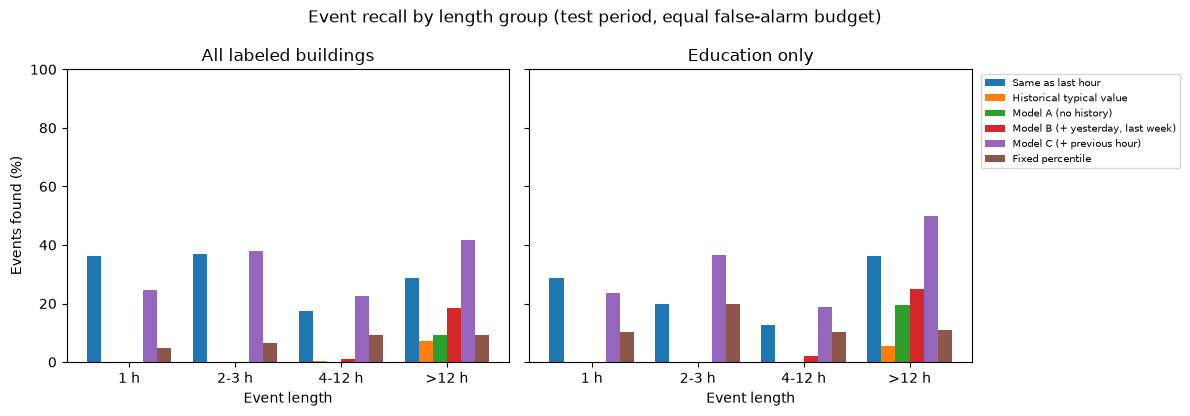

saved: eval_summary_test.csv, eval_by_length_test.csv, eval_recall_by_length_test.png


In [53]:
import matplotlib.pyplot as plt

tag = EVAL_SPLIT
summary.to_csv(OUT_DIR / f"eval_summary_{tag}.csv", index=False)
by_len.to_csv(OUT_DIR / f"eval_by_length_{tag}.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, scope in zip(axes, ["All labeled buildings", "Education only"]):
    sub = by_len[by_len["scope"] == scope]
    width = 0.8 / len(methods)
    for i, m in enumerate(methods):
        s = sub[sub["method"] == PRETTY.get(m, m)].set_index("length_group").reindex(LENGTH_LABELS)
        ax.bar(np.arange(len(LENGTH_LABELS)) + i * width, s["recall_pct"], width, label=PRETTY.get(m, m))
    ax.set_xticks(np.arange(len(LENGTH_LABELS)) + width * (len(methods) - 1) / 2)
    ax.set_xticklabels(LENGTH_LABELS)
    ax.set_title(scope)
    ax.set_xlabel("Event length")
axes[0].set_ylabel("Events found (%)")
axes[0].set_ylim(0, 100)
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle(f"Event recall by length group ({EVAL_SPLIT} period, equal false-alarm budget)")
plt.tight_layout()
plt.savefig(OUT_DIR / f"eval_recall_by_length_{tag}.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved:", f"eval_summary_{tag}.csv, eval_by_length_{tag}.csv, eval_recall_by_length_{tag}.png")

## 7. How to read and report this

1. **Start with the comparison at equal alarm budget.** Look at recall for A, B and C. If B and C are clearly above A, recent history matters. If they are close, say so: that is also a finding.
2. **Check against the simple methods.** If the same-as-last-hour baseline or the fixed percentile is close to the model, the model is not adding much for this label set. Say that directly.
3. **Look at the length groups.** Report where the methods differ and where they do not. Groups with few events are unclear.
4. **Expect the same-as-last-hour baseline to look different.** It flags the hour an event starts and the hour after it ends (because the previous hour was the anomaly), so its hour share is low and its flag-after share is high. That is a property of the method, not a bug. Judge it on recall and delay.
5. **Report precision with its caveat.** Unlabeled hours are treated as normal, so precision is probably understated.
6. **Check the false-alarm column.** If the test rate is far from the validation target for one method, that cut-off did not carry over well. Report it.
7. **Do not tune anything now.** Cut-offs, features and settings were fixed before looking at test results. Anything you change after this must be described as a new version.

Negative or inconclusive results are acceptable for the midterm as long as they are checked and explained.

**Next:** Part E, the planned experiments (feature sets, detector comparison, optional synthetic injection), and Part F, the figures for the report and slides.

In [54]:
free_memory("Part D done")

[memory freed] Part D done | elapsed 1.5 min


# Part E: Fair comparison at equal alarm rates

**Why this notebook exists.** In Part D, each predictor used the cut-off set on validation. On the test period those cut-offs gave very different alarm rates (for example about 0.08% of normal hours for the history-free models, 0.48% for model C, and 1.9% for the fixed percentile). A method that raises more alarms finds more events, so those recall numbers are not a fair comparison.

**What this notebook does.** For every predictor it sets the threshold so that the **same share of hours** is flagged, then measures how many labeled events are found. It repeats this over a range of alarm rates, which gives a **recall versus alarm rate** curve for each predictor. The curve does not depend on how any one cut-off was calibrated.

**Two ways to set the threshold**
- **pooled:** one threshold over all buildings, using the error score from Part C.
- **per building:** each building flags its own highest-scoring hours, so every building raises about the same share of alarms and no few buildings dominate.

**No labels are used to set thresholds.** Thresholds come from the score distribution of all valid hours in the evaluated period. Labels are used only afterwards to count found events. This is an analysis of the predictors, not a replacement for the frozen cut-offs of Part C. Report both, and say which is which.

**Alarm rates here are shares of all valid hours.** About 2% of hours in these buildings are labeled anomalies, so at a 0.5% alarm rate the flags cannot cover every labeled hour. Event recall can still be high, because one flagged hour inside an event is enough.

Run the cells in order. Cells marked **CHANGE** may need your file names.

## 0. Settings for this part

The shared paths, dates and rules are in the master settings cell at the top of the notebook. Only settings specific to this part are here.

In [55]:
from pathlib import Path
import numpy as np
import pandas as pd

FLAG_FILE   = str(OUT_DIR / "flags.parquet")                # from Part C (falls back to flags.csv.gz)
EVENT_FILE  = str(OUT_DIR / "lead_events.csv")              # from Part A
INFO_FILE   = str(OUT_DIR / "labeled_buildings_info.csv")   # from Part A
FIXED_FILE  = str(OUT_DIR / "cut_fixed_thresholds.csv")     # from Part C

RATES_PCT      = [0.1, 0.25, 0.5, 1, 2, 5]    # share of valid hours flagged, in percent
REPORT_RATE    = 1.0                          # the alarm rate used for the length-group table
MODES          = ["pooled", "per_building"]
MAX_ZERO_SHARE = 0.5
RUN_GAP_HOURS  = 1
MIN_EVENTS     = 20
LENGTH_LABELS  = ["1 h", "2-3 h", "4-12 h", ">12 h"]

PRETTY = {"last_hour": "Same as last hour", "typical": "Historical typical value",
          "A": "Model A (no history)", "B": "Model B (+ yesterday, last week)",
          "C": "Model C (+ previous hour)", "fixed": "Fixed percentile"}

## 1. Load flags and events

**What happens:** the score for every valid hour is loaded from the Part C flags file. For the fixed percentile (which has no error score) the score is the reading divided by the building's fixed threshold. Events are filtered exactly as in Part D, so the event counts match.

**What to check:** the event count should match the number in Part D for the same split (587 for test in your run).

In [56]:
def read_any(path):
    p = Path(path)
    stem = p.name.split(".")[0]
    for c in [p, p.with_name(stem + ".csv.gz"), p.with_name(stem + ".csv"), p.with_name(stem + ".parquet")]:
        if c.exists():
            print("reading", c)
            return pd.read_parquet(c) if c.suffix == ".parquet" else pd.read_csv(c)
    raise FileNotFoundError(f"Could not find {path}. Run Part C first.")

flags = read_any(FLAG_FILE)
flags["timestamp"] = pd.to_datetime(flags["timestamp"])
flags = flags[flags["split"] == EVAL_SPLIT].sort_values(["building_id", "timestamp"]).reset_index(drop=True)
flags["t"] = (flags["timestamp"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)

info = pd.read_csv(INFO_FILE).set_index("building_id")
flags["is_education"] = flags["building_id"].map(info["primary_use"]).eq("Education")

methods = [c[len("score_"):] for c in flags.columns if c.startswith("score_")]
if "flag_fixed" in flags.columns and Path(FIXED_FILE).exists():
    thr = pd.read_csv(FIXED_FILE, index_col="building_id")["fixed_threshold"]
    flags["score_fixed"] = flags["actual"] / flags["building_id"].map(thr)
    methods.append("fixed")
valid = flags["valid"].to_numpy()
print("methods:", methods, "| valid hours in", EVAL_SPLIT, ":", int(valid.sum()))

ev = pd.read_csv(EVENT_FILE, parse_dates=["start", "end"])
ev["split"] = ev["split"].replace({"validation": "val"})
ev = ev[(ev["split"] == EVAL_SPLIT) & (ev["zero_share"] <= MAX_ZERO_SHARE)
        & ev["building_id"].isin(flags["building_id"].unique())].copy()
ev["s"] = (ev["start"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)
ev["e"] = (ev["end"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)

def times_by_building(mask):
    sub = flags[mask]
    return {b: g["t"].to_numpy() for b, g in sub.groupby("building_id")}

def count_in(times, b, lo_t, hi_t):
    t = times.get(b)
    return 0 if t is None else int(np.searchsorted(t, hi_t, "right") - np.searchsorted(t, lo_t, "left"))

vt = times_by_building(flags["valid"])
ev["n_valid"] = [count_in(vt, b, s, e) for b, s, e in zip(ev["building_id"], ev["s"], ev["e"])]
ev = ev[ev["n_valid"] > 0].reset_index(drop=True)
ev["length_group"] = pd.Categorical(ev["length_group"], LENGTH_LABELS, ordered=True)
print("usable events in", EVAL_SPLIT, ":", len(ev))

reading outputs/flags.parquet
methods: ['last_hour', 'typical', 'A', 'B', 'C', 'fixed'] | valid hours in test : 257993
usable events in test : 587


## 2. Set thresholds at equal alarm rates and count found events

**What happens:** for each predictor, each threshold mode and each alarm rate:
1. The threshold is set so that the chosen share of **all valid hours** is flagged (pooled: one global threshold; per building: each building flags its own top share).
2. Flagged hours are grouped into runs.
3. Measured: **event recall** (events with at least one flagged hour), **run precision** (flagged runs touching a labeled hour), **hour precision** (flagged hours that are labeled), and the **actual** share of hours flagged.

Ties can make the actual share slightly different from the target, so the actual share is reported.

In [57]:
def flag_mask(score, mode, rate_pct):
    s = pd.Series(score, index=flags.index).where(flags["valid"])
    if mode == "pooled":
        thr = np.nanquantile(s.to_numpy(), 1 - rate_pct / 100)
        return (s > thr).fillna(False).to_numpy()
    pct = s.groupby(flags["building_id"]).rank(pct=True, method="first")
    return (pct > 1 - rate_pct / 100).fillna(False).to_numpy()

def runs_hit_rate(mask):
    sub = flags[mask]
    if sub.empty:
        return np.nan, 0
    gap = sub.groupby("building_id")["t"].diff()
    rid = (gap.isna() | (gap > RUN_GAP_HOURS)).cumsum()
    hit = sub.groupby(rid)["label"].max()
    return float(hit.mean()), int(len(hit))

def event_found(mask):
    times = times_by_building(pd.Series(mask, index=flags.index))
    return np.array([count_in(times, b, s, e) > 0 for b, s, e in zip(ev["building_id"], ev["s"], ev["e"])])

rows, found_store = [], {}
for mode in MODES:
    for m in methods:
        for r in RATES_PCT:
            mask = flag_mask(flags["score_" + m].to_numpy(), mode, r)
            f = event_found(mask)
            found_store[(mode, m, r)] = f
            run_prec, n_runs = runs_hit_rate(mask)
            edu = ev["is_education"].to_numpy()
            rows.append({"mode": mode, "method": PRETTY.get(m, m), "target_rate_pct": r,
                         "actual_rate_pct": 100 * mask.sum() / valid.sum(),
                         "events": len(ev), "recall_pct": 100 * f.mean(),
                         "recall_education_pct": 100 * f[edu].mean() if edu.any() else np.nan,
                         "runs": n_runs, "run_precision_pct": 100 * run_prec if n_runs else np.nan,
                         "hour_precision_pct": 100 * flags.loc[mask, "label"].mean() if mask.any() else np.nan})
curve = pd.DataFrame(rows)
curve.round(2).to_csv(OUT_DIR / f"eval_equal_rate_{EVAL_SPLIT}.csv", index=False)

pd.set_option("display.width", 220)
for mode in MODES:
    print(f"\nEvent recall (%) at equal alarm rates, threshold mode: {mode}")
    t = curve[curve["mode"] == mode].pivot(index="method", columns="target_rate_pct", values="recall_pct")
    t.columns = [f"{c}% of hours" for c in t.columns]
    print(t.reindex([PRETTY.get(m, m) for m in methods]).round(1).to_string())


Event recall (%) at equal alarm rates, threshold mode: pooled
                                  0.1% of hours  0.25% of hours  0.5% of hours  1.0% of hours  2.0% of hours  5.0% of hours
method                                                                                                                     
Same as last hour                          15.3            21.8           31.3           37.6           42.6           52.3
Historical typical value                    0.9             1.5            2.2            4.8            7.8           16.7
Model A (no history)                        1.0             2.9            4.8            5.6           12.9           22.5
Model B (+ yesterday, last week)            1.4             3.6            6.6           10.2           15.7           27.3
Model C (+ previous hour)                   4.3            12.4           25.0           33.2           45.0           58.9
Fixed percentile                            0.5             0.5      

## 3. Summary: precision at an equal alarm rate, and the area under the curve

**What happens:** two compact comparisons.
- **Run precision at the report rate** (`REPORT_RATE`, 1% of hours by default): of the flagged runs, how many touch a labeled hour.
- **Average recall across the alarm rates:** a single number per predictor, a rough area under the recall curve. It does not depend on any one cut-off.

In [58]:
summ = []
for mode in MODES:
    for m in methods:
        sub = curve[(curve["mode"] == mode) & (curve["method"] == PRETTY.get(m, m))]
        at = sub[np.isclose(sub["target_rate_pct"], REPORT_RATE)].iloc[0]
        summ.append({"mode": mode, "method": PRETTY.get(m, m),
                     f"recall_at_{REPORT_RATE}%": at["recall_pct"],
                     f"run_precision_at_{REPORT_RATE}%": at["run_precision_pct"],
                     f"hour_precision_at_{REPORT_RATE}%": at["hour_precision_pct"],
                     "mean_recall_over_rates": sub["recall_pct"].mean()})
summary = pd.DataFrame(summ)
summary.round(1).to_csv(OUT_DIR / f"eval_equal_rate_summary_{EVAL_SPLIT}.csv", index=False)
print(summary.round(1).to_string(index=False))

        mode                           method  recall_at_1.0%  run_precision_at_1.0%  hour_precision_at_1.0%  mean_recall_over_rates
      pooled                Same as last hour            37.6                   11.0                    11.5                    33.5
      pooled         Historical typical value             4.8                   16.6                    16.7                     5.7
      pooled             Model A (no history)             5.6                    9.6                    21.8                     8.3
      pooled Model B (+ yesterday, last week)            10.2                    9.2                    28.3                    10.8
      pooled        Model C (+ previous hour)            33.2                   17.9                    28.8                    29.8
      pooled                 Fixed percentile             1.7                   14.1                     5.0                     3.3
per_building                Same as last hour            38.7        

## 4. Recall by event length at the report rate

**What happens:** event recall split by length group, at the same alarm rate for every predictor, for both threshold modes. Groups with fewer than `MIN_EVENTS` events are marked.

In [59]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (max(0.0, c - h), c + h)

rows = []
for mode in MODES:
    for scope in ["All labeled buildings", "Education only"]:
        em = np.ones(len(ev), bool) if scope.startswith("All") else ev["is_education"].to_numpy()
        for lg in LENGTH_LABELS:
            gm = em & (ev["length_group"] == lg).to_numpy()
            n = int(gm.sum())
            for m in methods:
                k = int(found_store[(mode, m, REPORT_RATE)][gm].sum())
                lo, hi = wilson(k, n)
                rows.append({"mode": mode, "scope": scope, "length_group": lg, "method": PRETTY.get(m, m),
                             "events": n, "found": k, "recall_pct": round(100 * k / n, 1) if n else np.nan,
                             "low_pct": round(100 * lo, 1), "high_pct": round(100 * hi, 1), "few_events": n < MIN_EVENTS})
bylen = pd.DataFrame(rows)
bylen.to_csv(OUT_DIR / f"eval_equal_rate_by_length_{EVAL_SPLIT}.csv", index=False)
for mode in MODES:
    print(f"\nRecall (%) by event length at {REPORT_RATE}% of hours flagged, all labeled buildings, mode: {mode}")
    sub = bylen[(bylen["mode"] == mode) & (bylen["scope"] == "All labeled buildings")]
    tab = sub.pivot(index="method", columns="length_group", values="recall_pct")[LENGTH_LABELS]
    cnt = sub[sub["method"] == sub["method"].iloc[0]].set_index("length_group")["events"]
    tab.columns = [f"{c} (n={cnt[c]})" for c in LENGTH_LABELS]
    print(tab.reindex([PRETTY.get(m, m) for m in methods]).to_string())


Recall (%) by event length at 1.0% of hours flagged, all labeled buildings, mode: pooled
                                  1 h (n=212)  2-3 h (n=92)  4-12 h (n=185)  >12 h (n=98)
method                                                                                   
Same as last hour                        42.5          55.4            25.9          32.7
Historical typical value                  0.0           3.3             2.7          20.4
Model A (no history)                      0.0           3.3             3.8          23.5
Model B (+ yesterday, last week)          0.5           7.6             9.2          35.7
Model C (+ previous hour)                26.9          46.7            28.1          43.9
Fixed percentile                          0.0           2.2             2.7           3.1

Recall (%) by event length at 1.0% of hours flagged, all labeled buildings, mode: per_building
                                  1 h (n=212)  2-3 h (n=92)  4-12 h (n=185)  >12 h (n=98)
meth

## 5. Figure: recall versus alarm rate

**What happens:** one panel per threshold mode. The higher a line is at a given alarm rate, the more events that predictor finds for the same cost. Saved for the report and slides.

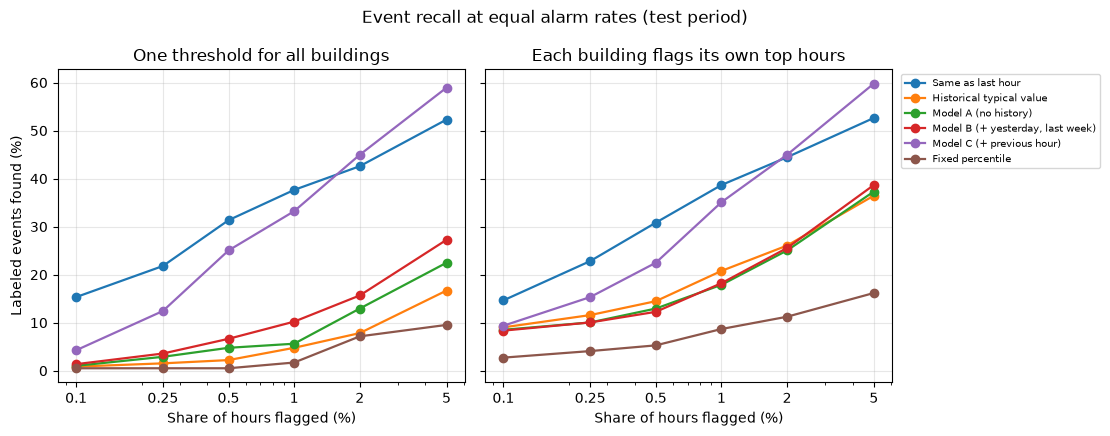

saved: eval_equal_rate_test.csv, eval_equal_rate_summary_test.csv, eval_equal_rate_by_length_test.csv, eval_equal_rate_curve_test.png


In [60]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(MODES), figsize=(5.6 * len(MODES), 4.4), sharey=True)
axes = np.atleast_1d(axes)
for ax, mode in zip(axes, MODES):
    for m in methods:
        sub = curve[(curve["mode"] == mode) & (curve["method"] == PRETTY.get(m, m))]
        ax.plot(sub["target_rate_pct"], sub["recall_pct"], marker="o", lw=1.6, label=PRETTY.get(m, m))
    ax.set_xscale("log")
    ax.set_xticks(RATES_PCT)
    ax.set_xticklabels([str(r) for r in RATES_PCT])
    ax.set_xlabel("Share of hours flagged (%)")
    ax.set_title("One threshold for all buildings" if mode == "pooled" else "Each building flags its own top hours")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Labeled events found (%)")
axes[-1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle(f"Event recall at equal alarm rates ({EVAL_SPLIT} period)")
plt.tight_layout()
plt.savefig(OUT_DIR / f"eval_equal_rate_curve_{EVAL_SPLIT}.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved: eval_equal_rate_%s.csv, eval_equal_rate_summary_%s.csv, eval_equal_rate_by_length_%s.csv, eval_equal_rate_curve_%s.png" % ((EVAL_SPLIT,) * 4))

## 6. How to read and report this

1. **Compare lines at the same alarm rate.** This is the fair comparison. If a predictor is above another at every rate, it is better at finding labeled events for the same alarm cost.
2. **Report both threshold modes.** If they agree on the order of the predictors, say so; the finding is then robust to how the threshold is set. If they disagree, say that too.
3. **Keep the Part D numbers, and label them.** Part D is the result of the pre-set cut-offs; this notebook is the equal-rate analysis. State plainly that the cut-offs did not carry over equally from validation to test.
4. **The comparison with the simple baseline matters.** If the same-as-last-hour predictor is close to model C, then the previous hour does most of the work, and the model adds little beyond it for this label set.
5. **Short events are the test of whether a method adds value.** Compare the 1 h and 2-3 h columns.
6. **Do not overclaim.** Labels are human judgments from plots, LEAD comes from the same source as GEPIII, and unlabeled hours are treated as normal. Event counts inside one building are not independent.

In [61]:
free_memory("Part E done")

[memory freed] Part E done | elapsed 1.5 min


# Results to copy back

The cell below prints every result table in one place. These are the numbers the report and the slides use.

In [62]:
def show(fname, title):
    p = OUT_DIR / fname
    print("=" * 100); print(title, "|", fname)
    if p.exists():
        print(pd.read_csv(p).to_string(index=False))
    else:
        print("(file not found)")

show("table_data_checks.csv", "Data checks")
show("predictor_accuracy.csv", "Accuracy of the predictors (test, validation)")
show("eval_summary_test.csv", "Pre-set cut-offs: summary")
show("eval_by_length_test.csv", "Pre-set cut-offs: recall by event length")
show("eval_equal_rate_summary_test.csv", "Equal alarm rates: summary")
show("eval_equal_rate_by_length_test.csv", "Equal alarm rates: recall by event length")
show("eval_equal_rate_test.csv", "Equal alarm rates: curve")
print()
print("Files in", OUT_DIR, ":")
for p in sorted(OUT_DIR.iterdir()):
    print(f"  {p.name:45s} {p.stat().st_size/1e6:8.2f} MB")
print(f"\nTotal run time: {(time.time() - T_START)/60:.1f} min")

Data checks | table_data_checks.csv
                                     Unnamed: 0       value
                                      buildings     200.000
                                           rows 1749494.000
                           exact duplicate rows       0.000
              duplicate building-timestamp rows       0.000
                              negative readings       0.000
                               missing readings       0.000
                            exact zero readings   70157.000
                       share of exact zeros (%)       4.010
rows not exactly 1 h after the previous row (%)       0.074
                     row-based lag_24 wrong (%)       0.890
Accuracy of the predictors (test, validation) | predictor_accuracy.csv
split                        predictor  hours  MAE_kWh  RMSE_kWh    R2  RMSLE
  val                Same as last hour 249407     9.10     49.09 0.984  0.234
  val         Historical typical value 249407    23.18     65.28 0.971  0.753